# 01.1 Neighbourhood re-evaluation (Gaia DR3, within 100 pc)

Sub-notebook of `01_neighborhood_hrd.ipynb`. It answers the open questions of notebook 01 with reference data instead of assumptions. Literature for every number used here: `../literature.md`, Section 8.

| # | Question from notebook 01 | Main test | Reference data |
|---|---|---|---|
| 1 | Why does the completeness curve of the brightest class (M_G < 5) rise with distance, even without a RUWE cut? | Count the nearby bright stars that Gaia misses, using Hipparcos | Hipparcos (GAVO), Gaia-Hipparcos cross-match (AIP), GCNS list of known stars missing from Gaia |
| 2 | How pure and how complete was the Hyades window search of section 8.3? | Match our candidates by source_id with published member lists | GCNS Hyades candidates, Hunt & Reffert 2024 |
| 3 | How does the cleaned sample compare with the Gaia Catalogue of Nearby Stars (GCNS)? | Per brightness class: which GCNS stars we keep, which we lose and why, which we have that GCNS rejected | GCNS (GAVO) |
| 4 | Why is RUWE failure highest at 30 to 50 pc for M_G 5 to 10? | Remove the Hyades; split by image-window double peaks; search resolved pairs; drop the colour cuts | GCNS, GCNS resolved pairs |
| 5 | Do stars with more Gaia observations fail RUWE more often (test power)? | Failure rate by `visibility_periods_used` at fixed class and distance, with and without control for ecliptic latitude | our download |

**How each check is written.** Before the code: what is done, why, what it costs, the competing hypotheses and which result supports or refutes each. After the code: "How to read it" and an empty "Record your reading here". Variables you may change are in capitals at the top of a code cell.

**Data.** Nothing new is downloaded from the Gaia archive except one small cross-match table (99 524 rows from AIP Potsdam). The GCNS and Hipparcos tables come from the GAVO Data Center in Heidelberg, which is not affected by the Gaia archive downtime before DR4. The Hunt & Reffert list comes from VizieR, through the same route as in notebook 02. Each download is saved in `data/raw/01-01.1_*.fits` with the query text in a `.adql` file next to it. The second run loads the files and needs no internet. Downloads take a few minutes in total; the largest is the GCNS table (about 40 MB).

## 1. Setup

Same as notebook 01: the base folder is found by walking up from the notebook folder. A few helper functions used throughout are defined here: the completeness curve of notebook 01, binomial confidence intervals, and a cached download for any TAP service.

In [1]:
import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from astropy.table import Table
from astropy.coordinates import SkyCoord
import astropy.units as u

here = Path.cwd().resolve()
base = next(p for p in [here, *here.parents] if (p / "shared" / "config.py").exists())
if str(base / "shared") not in sys.path:
    sys.path.insert(0, str(base / "shared"))

import config
from gaia_tools import query_gaia_cached, bp_rp_excess_corrected, sigma_c_star, absolute_mag

PROJECT = config.project_dir("01_gaia")
FIG = PROJECT / "figures"

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 10,
                     "axes.grid": False, "savefig.bbox": "tight"})

# TAP services. query_gaia_cached() accepts any list of (name, URL); it caches the result and writes the .adql file.
GAVO = [("GAVO Data Center, Heidelberg", "https://dc.g-vo.org/tap")]
GAIA_MIRRORS = [("AIP Potsdam (Gaia partner data centre)", "https://gaia.aip.de/tap"),
                ("ARI Heidelberg (Gaia partner data centre)", "https://gaia.ari.uni-heidelberg.de/tap")]

CLASSES = [(-5, 5, "M_G < 5"), (5, 10, "M_G 5-10"), (10, 13, "M_G 10-13"), (13, 25, "M_G > 13")]
D_GRID = np.linspace(15, 100, 171)     # distances at which N(<d)/d^3 is evaluated, as in notebook 01
REF_ZONE = (20, 30)                    # normalisation zone, as in notebook 01
DBINS = [15, 30, 50, 75, 100]          # distance bins of the RUWE tables, as in notebook 01


def completeness_curve(dist, d_grid=D_GRID, ref=REF_ZONE):
    """N(<d)/d^3, normalised to its mean in the reference zone (notebook 01, section 8.1)."""
    d = np.sort(np.asarray(dist, dtype=float))
    ratio = np.searchsorted(d, d_grid, side="right") / d_grid**3
    r = (d_grid >= ref[0]) & (d_grid <= ref[1])
    return ratio / np.nanmean(ratio[r])


def curve_at(curve, d, d_grid=D_GRID):
    return float(np.interp(d, d_grid, curve))


def in_class(mg, lo, hi):
    return (mg >= lo) & (mg < hi)


def wilson(k, n, z=1.96):
    """Share k/n in percent with a 95 % Wilson interval (works also for small n and shares near 0)."""
    if n == 0:
        return np.nan, np.nan, np.nan
    p = k / n
    den = 1 + z**2 / n
    mid = (p + z**2 / (2 * n)) / den
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / den
    return 100 * p, 100 * (mid - half), 100 * (mid + half)


def angsep_deg(l1, b1, l2, b2):
    l1, b1, l2, b2 = map(np.radians, (l1, b1, l2, b2))
    c = np.sin(b1) * np.sin(b2) + np.cos(b1) * np.cos(b2) * np.cos(l1 - l2)
    return np.degrees(np.arccos(np.clip(c, -1, 1)))


def load_cached(name, adql, services, force=False):
    """Download once (any TAP service), then load from data/raw/01-01.1_<name>.fits. Column names in lower case."""
    path = config.RAW / f"01-01.1_{name}.fits"
    side = path.with_suffix(".adql")
    if path.exists() and side.exists() and not force and adql.strip() not in side.read_text(encoding="utf-8"):
        print(f"Note: the query text for {path.name} changed since the download. "
              "Set FORCE_DOWNLOAD = True to fetch it again.")
    tab = query_gaia_cached(adql, path, overwrite=force, services=services)
    out = tab.to_pandas()
    out.columns = [c.lower() for c in out.columns]
    return out


print("Base folder:", config.BASE)
print("Figures go to:", FIG)
print("numpy", np.__version__, "| pandas", pd.__version__, "| matplotlib", matplotlib.__version__)

Base folder: H:\Astronomie
Figures go to: H:\Astronomie\projects\01_gaia\figures
numpy 2.2.6 | pandas 2.3.3 | matplotlib 3.10.9


## 2. The data of notebook 01, with the same cuts

**What.** Load the raw download of notebook 01 (parallax ≥ 10 mas, parallax_over_error ≥ 10) and recompute the four quality cuts as flags, one column per cut, instead of deleting rows. Nothing is downloaded here.

**Why flags.** Several checks below need to know *which* cut removed a star, or need the sample without some of the cuts. With one flag per cut every variant is a simple combination: `other` = the three photometric cuts (G S/N, BP/RP S/N, C\*), `clean` = all four.

**What to look for.** The two numbers printed at the end must be 372,226 and 201,458, as in notebook 01. If they differ, the input file is not the one notebook 01 used.

In [2]:
RAW_FILE = config.RAW / "gaia_dr3_100pc_plx10_poe10.fits"
df = Table.read(RAW_FILE).to_pandas()
df.columns = [c.lower() for c in df.columns]

df["dist_pc"] = 1000.0 / df["parallax"]
df["mg"] = absolute_mag(df["phot_g_mean_mag"], df["parallax"])
df["c_star"] = bp_rp_excess_corrected(df["phot_bp_rp_excess_factor"], df["bp_rp"])
df["c_star_sigma"] = sigma_c_star(df["phot_g_mean_mag"])

df["ok_ruwe"] = df["ruwe"] < 1.4
df["ok_g"] = df["phot_g_mean_flux_over_error"] > 50
df["ok_bprp"] = (df["phot_bp_mean_flux_over_error"] > 20) & (df["phot_rp_mean_flux_over_error"] > 20)
df["ok_cstar"] = np.abs(df["c_star"]) < 3 * df["c_star_sigma"]
df["other"] = df["ok_g"] & df["ok_bprp"] & df["ok_cstar"]      # photometric cuts only
df["clean"] = df["other"] & df["ok_ruwe"]                       # all four cuts
df["fail_ruwe"] = df["ruwe"] >= 1.4

print(f"Downloaded (notebook 01):   {len(df):,}   (notebook 01: 372,226)")
print(f"Clean after all four cuts:  {int(df['clean'].sum()):,}   (notebook 01: 201,458)")

Downloaded (notebook 01):   372,226   (notebook 01: 372,226)
Clean after all four cuts:  201,458   (notebook 01: 201,458)


## 3. Downloads (small, cached)

**What.** Seven tables, each reduced on the server to the columns we need.

| File in `data/raw/` | Service | Content | Used in |
|---|---|---|---|
| `01-01.1_gcns_main` | GAVO, `gcns.main` | 331 312 GCNS objects, 15 columns | Q3, Q4 |
| `01-01.1_gcns_hyacob` | GAVO, `gcns.hyacob` | 920 Hyades and 212 Coma Ber candidates | Q1, Q2, Q4 |
| `01-01.1_gcns_resolvedss` | GAVO, `gcns.resolvedss` | resolved pairs found by the GCNS team | Q4 |
| `01-01.1_hipparcos_main` | GAVO, `hipparcos.main` | Hipparcos catalogue (1997), 9 columns, all 118 218 entries | Q1 |
| `01-01.1_gcns_missing_hip` | GAVO, `gcns.missing_10mas` joined on the server with `hipparcos.main` | 1258 known stars with parallax > 10 mas that are missing from Gaia, with Hipparcos magnitudes where they exist | Q1 |
| `01-01.1_hip2_best_neighbour_dr3` | AIP, `gaiadr3.hipparcos2_best_neighbour` joined with `gaia_source` | the official Gaia counterpart of each Hipparcos star, with its Gaia parallax and G | Q1 |
| `01-01.1_hunt_reffert_hyades` | VizieR web interface (astroquery), J/A+A/686/A42/members | Hunt & Reffert 2024 members of Melotte 25 (the Hyades) | Q2 |

**Why Hipparcos in full.** The GAVO table states parallaxes in degrees, not in mas. To be safe against a unit surprise, the whole catalogue is downloaded (about 8 MB) and the unit is checked in the next cell from the median parallax.

**Why the server-side join for the missing stars.** The GCNS list of missing stars has no magnitudes. A positional match against Hipparcos on the same server adds them. The match radius is generous (60 arcsec) because SIMBAD positions are for the year 2000 and Hipparcos positions for 1991.25; nearby stars move up to several arcseconds per year. Only the nearest match is kept.

**Cost.** GCNS and Hipparcos tables are under CC BY-NC 4.0 (GAVO) and ESA licences: fine for this non-commercial project, cite them. Raw files stay local and never go to GitHub; the `.adql` files do.

**Exercise.** None. If a download fails, run the cell again; a partially failed run saves nothing.

In [3]:
FORCE_DOWNLOAD = False         # True = download again even if the file exists
MATCH_RADIUS_ARCSEC = 60.0     # positional match of the missing-star list against Hipparcos

ADQL_GCNS = """
SELECT source_id, parallax, parallax_error,
       phot_g_mean_mag, phot_bp_mean_mag, phot_rp_mean_mag,
       phot_g_mean_flux_over_error, phot_bp_mean_flux_over_error, phot_rp_mean_flux_over_error,
       phot_bp_rp_excess_factor, ruwe, ipd_frac_multi_peak, gcns_prob, dist_1, dist_50
FROM gcns.main
"""
ADQL_HYACOB = "SELECT source_id, name, c_cluster, dist_cluster FROM gcns.hyacob"
ADQL_RESOLVED = "SELECT * FROM gcns.resolvedss"
ADQL_HIP = """
SELECT hipno, ra, dec, vmag, hpmag, parallax, e_parallax, sptype, multflag
FROM hipparcos.main
"""
ADQL_MISSING = f"""
SELECT m.main_id, m.ra, m.dec, m.plx_value, m.plx_bibcode, m.otype,
       h.hipno, h.vmag, h.hpmag,
       DISTANCE(POINT('ICRS', m.ra, m.dec), POINT('ICRS', h.ra, h.dec)) * 3600.0 AS sep_arcsec
FROM gcns.missing_10mas AS m
LEFT OUTER JOIN hipparcos.main AS h
  ON 1 = CONTAINS(POINT('ICRS', h.ra, h.dec), CIRCLE('ICRS', m.ra, m.dec, {MATCH_RADIUS_ARCSEC / 3600.0}))
"""

gcns = load_cached("gcns_main", ADQL_GCNS, GAVO, FORCE_DOWNLOAD)
hyacob = load_cached("gcns_hyacob", ADQL_HYACOB, GAVO, FORCE_DOWNLOAD)
resolved = load_cached("gcns_resolvedss", ADQL_RESOLVED, GAVO, FORCE_DOWNLOAD)
hip = load_cached("hipparcos_main", ADQL_HIP, GAVO, FORCE_DOWNLOAD)
missing = load_cached("gcns_missing_hip", ADQL_MISSING, GAVO, FORCE_DOWNLOAD)

# Hipparcos parallax unit: degrees (GAVO convention) or mas? Median Hipparcos parallax is a few mas.
scale = 3.6e6 if np.nanmedian(np.abs(hip["parallax"])) < 1e-3 else 1.0
hip["plx_mas"] = hip["parallax"] * scale
hip["e_plx_mas"] = hip["e_parallax"] * scale
print(f"Hipparcos parallax unit detected: {'degrees' if scale > 1 else 'mas'}; "
      f"median parallax {np.nanmedian(hip['plx_mas']):.2f} mas (expected: a few mas)")

for name, t in [("gcns.main", gcns), ("gcns.hyacob", hyacob), ("gcns.resolvedss", resolved),
                ("hipparcos.main", hip), ("missing_10mas x Hipparcos (rows, before keeping the nearest match)", missing)]:
    print(f"{name:70s} {len(t):>8,} rows")
print("\nCluster names in gcns.hyacob:\n" + hyacob["name"].astype(str).str.strip().value_counts().to_string())

Loading cached result: H:\Astronomie\data\raw\01-01.1_gcns_main.fits
Trying GAVO Data Center, Heidelberg (https://dc.g-vo.org/tap) ...
  reachable. Job submitted, waiting for the result (can take several minutes) ...
Saved 1132 rows from GAVO Data Center, Heidelberg to H:\Astronomie\data\raw\01-01.1_gcns_hyacob.fits
Trying GAVO Data Center, Heidelberg (https://dc.g-vo.org/tap) ...
  reachable. Job submitted, waiting for the result (can take several minutes) ...
Saved 19176 rows from GAVO Data Center, Heidelberg to H:\Astronomie\data\raw\01-01.1_gcns_resolvedss.fits
Trying GAVO Data Center, Heidelberg (https://dc.g-vo.org/tap) ...
  reachable. Job submitted, waiting for the result (can take several minutes) ...
Saved 117955 rows from GAVO Data Center, Heidelberg to H:\Astronomie\data\raw\01-01.1_hipparcos_main.fits
Trying GAVO Data Center, Heidelberg (https://dc.g-vo.org/tap) ...
  reachable. Job submitted, waiting for the result (can take several minutes) ...
Saved 1323 rows from GAVO 

In [4]:
ADQL_BN = """
SELECT b.original_ext_source_id AS hip, b.source_id, b.angular_distance, b.number_of_neighbours,
       g.parallax, g.parallax_over_error, g.phot_g_mean_mag, g.bp_rp, g.ruwe, g.astrometric_params_solved
FROM gaiadr3.hipparcos2_best_neighbour AS b
JOIN gaiadr3.gaia_source AS g ON g.source_id = b.source_id
"""
bn = load_cached("hip2_best_neighbour_dr3", ADQL_BN, GAIA_MIRRORS, FORCE_DOWNLOAD)
bn = bn.rename(columns={"parallax": "g_parallax", "parallax_over_error": "g_poe", "phot_g_mean_mag": "g_gmag",
                        "bp_rp": "g_bp_rp", "ruwe": "g_ruwe", "astrometric_params_solved": "g_params"})
bn["source_id"] = bn["source_id"].astype("Int64")      # nullable integer: never let 19-digit IDs become floats
bn["hip"] = bn["hip"].astype("int64")
print(f"Gaia DR3 counterparts of Hipparcos stars: {len(bn):,} rows (expected 99,524)")

Trying AIP Potsdam (Gaia partner data centre) (https://gaia.aip.de/tap) ...
  reachable. Job submitted, waiting for the result (can take several minutes) ...
Saved 99524 rows from AIP Potsdam (Gaia partner data centre) to H:\Astronomie\data\raw\01-01.1_hip2_best_neighbour_dr3.fits
Gaia DR3 counterparts of Hipparcos stars: 99,524 rows (expected 99,524)


In [5]:
HR_CATALOGUE = "J/A+A/686/A42/members"          # Hunt & Reffert 2024, as in notebook 02
HR_NAMES = ["Melotte_25", "Melotte 25", "Hyades"]  # tried in this order
AQ_SERVERS = ["vizier.cds.unistra.fr", "vizier.cfa.harvard.edu", "vizier.nao.ac.jp"]
HR_FILE = config.RAW / "01-01.1_hunt_reffert_hyades.fits"
HR_COLS = {"Name": "hr_cluster", "GaiaDR3": "source_id", "Prob": "hr_prob", "inrt": "hr_in_rt",
           "inrj": "hr_in_rj", "Gmag": "hr_gmag", "Plx": "hr_plx", "RA_ICRS": "hr_ra", "DE_ICRS": "hr_dec"}


def fetch_hunt_reffert():
    # VizieR TAP was not reachable from this PC on 2026-11-18; the web interface via astroquery was (notebook 02).
    from astroquery.vizier import Vizier
    errors = []
    for server in AQ_SERVERS:
        for name in HR_NAMES:
            try:
                v = Vizier(vizier_server=server, columns=list(HR_COLS), row_limit=-1)
                v.TIMEOUT = 300
                res = v.query_constraints(catalog=HR_CATALOGUE, Name=name)
            except Exception as exc:
                errors.append(f"{server}, {name}: {type(exc).__name__}: {str(exc)[:100]}")
                break                                    # server problem: try the next server
            if len(res) and len(res[0]):
                t = res[0]
                if t["GaiaDR3"].dtype.kind not in "iu":
                    raise RuntimeError("GaiaDR3 arrived as a non-integer column; precision would be lost.")
                out = Table({new: np.ma.filled(t[old], np.nan if t[old].dtype.kind == "f" else
                                               (0 if t[old].dtype.kind in "iub" else ""))
                             for old, new in HR_COLS.items() if old in t.colnames})
                out.write(HR_FILE, overwrite=True)
                HR_FILE.with_suffix(".adql").write_text(
                    f"-- service: VizieR web interface via astroquery ({server})\n"
                    f"-- retrieved: {time.strftime('%Y-%m-%dT%H:%M:%S')}\n-- catalogue: Hunt & Reffert 2024, {HR_CATALOGUE}\n"
                    f"-- cluster: {name}\n-- rows: {len(out)}\n-- method: query_constraints Name={name}; columns: {list(HR_COLS)}\n",
                    encoding="utf-8")
                print(f"Saved {len(out)} Hunt & Reffert members of {name} from {server}")
                return
            errors.append(f"{server}, {name}: no rows")
    raise RuntimeError("Hunt & Reffert list not retrieved:\n  " + "\n  ".join(errors))


hr = None
try:
    if not HR_FILE.exists() or FORCE_DOWNLOAD:
        fetch_hunt_reffert()
    else:
        print(f"Loading cached result: {HR_FILE}")
    hr = Table.read(HR_FILE).to_pandas()
    hr["source_id"] = hr["source_id"].astype("int64")
    for c in ("hr_in_rt", "hr_in_rj"):
        if c in hr:
            hr[c] = hr[c].astype(int) == 1
    print(f"Hunt & Reffert 2024 Hyades members: {len(hr):,}"
          + (f", of which inside the King tidal radius: {int(hr['hr_in_rt'].sum()):,}" if "hr_in_rt" in hr else ""))
except Exception as exc:
    print("Hunt & Reffert list not available, question 2 uses the GCNS list only.\n", exc)

Saved 927 Hunt & Reffert members of Melotte_25 from vizier.cfa.harvard.edu
Hunt & Reffert 2024 Hyades members: 927, of which inside the King tidal radius: 386


## 4. Question 1: why does the brightest class rise?

**Recap.** In notebook 01 the curve N(<d)/d³ of the class M_G < 5 (A to G stars and giants), normalised to 20 to 30 pc, reached 1.21 at 50 and 90 pc even without a RUWE cut. A value above 1 means the *reference zone* is short of stars, not that distant stars are over-counted. Read backwards: 1/1.21 = 0.83, so about **17 % of the expected stars of this class are missing in the nearby volume**.

**Competing hypotheses and what would decide between them.**

| Hypothesis | Mechanism | Supported if | Refuted if |
|---|---|---|---|
| H1 Gaia's bright limit | Gaia does not contain stars brighter than about G = 3 and misses part of those brighter than G = 7; very bright stars can also lack a parallax or have a poor one. A nearby star of this class is bright on the sky, so it is lost preferentially *near* the Sun. | Hipparcos lists bright stars within about 30 to 40 pc that are missing from our download, they are nearly all brighter than Hp ≈ 6 to 7, and adding them back makes the curve flat (1.00 ± 0.05) | Far fewer missing stars than about 17 % of the class within 30 pc, or the missing stars are not bright, or the curve still rises after the correction |
| H2 noise in the reference zone | Only a few hundred stars of this class lie within 30 pc, so the normalisation itself is uncertain | the bootstrap 95 % interval of the value at 90 pc includes 1.0 | the interval lies clearly above 1.0 (rough expectation: ± 6 %) |
| H3 local structures | Clusters (Hyades at 47 pc, Coma Ber at 86 pc) add stars at particular distances | removing the GCNS cluster candidates changes the values by more than about 0.02 | the change stays below about 0.02 (expected, because the clusters contain only a few dozen bright stars) |
| H4 real density gradient | Stellar density falls with height above the Galactic plane | no rise at all; a gradient would make the curve *fall* with distance, and differently north and south | (sign argument) |

**Analogy.** A rarefaction curve that rises after normalisation means the normalisation sample is under-sampled, like a reference library from which the most abundant taxa were filtered out by a saturation artefact.

### 4.1 The curve without any cuts, and how noisy the normalisation is (H2)

**What.** The M_G < 5 curve for three samples: no cuts at all, photometric cuts only, all cuts. Then a bootstrap: draw the stars of the class with replacement many times, recompute the curve, and read the 2.5 and 97.5 percentiles of the value at 90 pc. This is the uncertainty that comes from having only a few hundred stars in the reference zone.

**Exercise.** Change `N_BOOT` to 200 or 3000: the interval should barely change (it is a property of the data, not of the number of resamples).

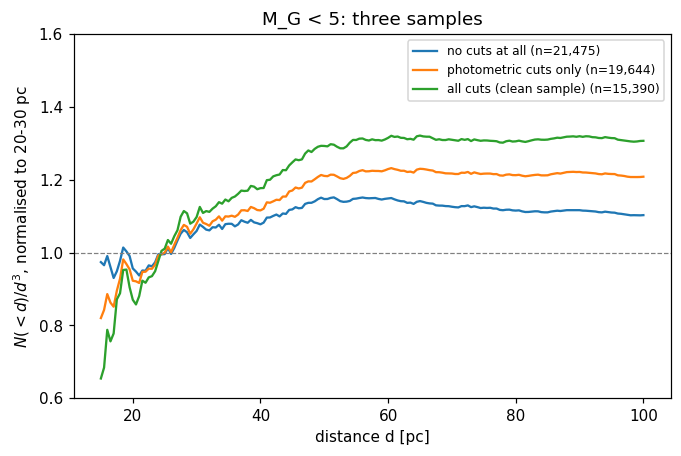

                 sample     n  n in 20-30 pc  ratio 50 pc  ratio 90 pc  90 pc: 2.5 %  90 pc: 97.5 %
         no cuts at all 21475            408         1.15         1.12          1.01           1.24
  photometric cuts only 19644            354         1.21         1.22          1.09           1.36
all cuts (clean sample) 15390            267         1.29         1.32          1.16           1.53


In [6]:
N_BOOT = 1000      # number of bootstrap resamples

lo, hi, label = CLASSES[0]
m_bright = in_class(df["mg"], lo, hi)
variants = [("no cuts at all", m_bright),
            ("photometric cuts only", m_bright & df["other"]),
            ("all cuts (clean sample)", m_bright & df["clean"])]

rng = np.random.default_rng(1)
rows = []
fig, ax = plt.subplots(figsize=(7, 4.3))
for name, sel in variants:
    dist = df.loc[sel, "dist_pc"].to_numpy()
    curve = completeness_curve(dist)
    boot = np.array([curve_at(completeness_curve(rng.choice(dist, len(dist))), 90) for _ in range(N_BOOT)])
    ax.plot(D_GRID, curve, label=f"{name} (n={len(dist):,})")
    rows.append((name, len(dist), int(((dist >= REF_ZONE[0]) & (dist < REF_ZONE[1])).sum()),
                 curve_at(curve, 50), curve_at(curve, 90), *np.percentile(boot, [2.5, 97.5])))
ax.axhline(1, color="grey", lw=0.8, ls="--")
ax.set_xlabel("distance d [pc]"); ax.set_ylabel(r"$N(<d)/d^3$, normalised to 20-30 pc")
ax.set_title("M_G < 5: three samples"); ax.legend(fontsize=8); ax.set_ylim(0.6, 1.6)
plt.show()

q1a = pd.DataFrame(rows, columns=["sample", "n", "n in 20-30 pc", "ratio 50 pc", "ratio 90 pc", "90 pc: 2.5 %", "90 pc: 97.5 %"])
print(q1a.to_string(index=False, float_format=lambda v: f"{v:.2f}"))

**How to read it.** The first row is the rise in its purest form: no quality cut can have caused it. The last two columns are the bootstrap interval. If 1.0 lies inside, the rise could be noise (H2 supported). If the interval lies well above 1.0, noise is ruled out and a real deficit near the Sun must be explained. Compare "n in 20-30 pc": it tells you how many stars the whole normalisation rests on.

**Record your reading here:**

### 4.2 Which nearby bright stars does Gaia miss? (H1, with Hipparcos)

**What.** Take every Hipparcos star with a Hipparcos parallax ≥ 10 mas. Look up its official Gaia DR3 counterpart (`hipparcos2_best_neighbour`) and sort it into one of five groups:

1. *in our download*: the counterpart is among our 372,226 sources;
2. *no Gaia match*: Gaia has no counterpart at all (typically the brightest stars);
3. *Gaia match without parallax*: Gaia has the star, but only a position (2-parameter solution);
4. *Gaia parallax ≥ 10 but poe < 10*: Gaia has a parallax, but too imprecise for our download cut;
5. *Gaia parallax < 10 mas*: Gaia places the star beyond 100 pc (mostly stars near the 100 pc edge where the two catalogues disagree a little; not a loss).

Groups 2 to 4 are stars that belong to the 100 pc volume but are missing from our download because of the way Gaia handles very bright stars.

**Why Hipparcos.** It is complete to V = 7.3 to 9 depending on direction (ESA). Every star that Gaia might lose at the bright end is therefore in Hipparcos. Gaia and Hipparcos are independent instruments, so this is a real external check.

**Cost and approximations.** Absolute magnitudes for Hipparcos stars use the Hipparcos magnitude Hp instead of G (for stars without a Gaia G). Hp and G are similar but not identical; 4.3 tests the effect by shifting Hp by ± 0.3 mag. This is my approximation, not a literature value. Hipparcos parallaxes (1997 catalogue) have errors around 1 mas, small compared with the parallaxes of the stars that matter here (25 mas and more within 40 pc).

**What to look for.** Groups 2 to 4 should be concentrated at Hp < 6 to 7 and, within the class M_hp < 5, at small distances.

In [7]:
PLX_MIN = 10.0
HP_BINS = [-2, 3, 4, 5, 6, 7, 8, 9, 13]
D_BINS_HIP = [0, 15, 20, 30, 40, 50, 75, 100]
MISSING_GROUPS = ["no Gaia match", "Gaia match without parallax", "Gaia parallax >= 10 but poe < 10"]

h = hip[hip["plx_mas"] >= PLX_MIN].copy()
h["dist_hip"] = 1000.0 / h["plx_mas"]
h["m_hp"] = h["hpmag"] + 5 * np.log10(h["plx_mas"]) - 10
h["hipno"] = h["hipno"].astype("int64")
h = h.merge(bn, left_on="hipno", right_on="hip", how="left")

matched = h["source_id"].notna()
in_dl = matched & h["source_id"].isin(df["source_id"])
nopar = matched & ~in_dl & h["g_parallax"].isna()
lowpoe = matched & ~in_dl & ~nopar & (h["g_parallax"] >= 10) & (h["g_poe"] < 10)
lowplx = matched & ~in_dl & ~nopar & (h["g_parallax"] < 10)
h["status"] = np.select([in_dl, ~matched, nopar, lowpoe, lowplx],
                        ["in our download", "no Gaia match", "Gaia match without parallax",
                         "Gaia parallax >= 10 but poe < 10", "Gaia parallax < 10 mas"], default="other")
print(f"Hipparcos stars with Hipparcos parallax >= {PLX_MIN} mas: {len(h):,}")
print(h["status"].value_counts().to_string())
if (h["status"] == "other").any():
    print("Warning: 'other' should be empty (a counterpart that passes our download cuts but is not in the download).")

print("\nBy Hipparcos magnitude Hp (all classes):")
print(pd.crosstab(pd.cut(h["hpmag"], HP_BINS), h["status"]).to_string())

cls = h["m_hp"] < 5
t = pd.crosstab(pd.cut(h.loc[cls, "dist_hip"], D_BINS_HIP), h.loc[cls, "status"])
t["missing (groups 2-4) [%]"] = 100 * t.reindex(columns=MISSING_GROUPS, fill_value=0).sum(axis=1) / t.sum(axis=1)
print("\nClass M_hp < 5, by Hipparcos distance [pc]:")
print(t.to_string(float_format=lambda v: f"{v:.1f}"))

Hipparcos stars with Hipparcos parallax >= 10.0 mas: 22,982
status
in our download                16276
no Gaia match                   4632
Gaia parallax < 10 mas          1890
Gaia match without parallax      184

By Hipparcos magnitude Hp (all classes):
status   Gaia match without parallax  Gaia parallax < 10 mas  in our download  no Gaia match
hpmag                                                                                       
(-2, 3]                            4                       1               23             76
(3, 4]                             6                       3              115             81
(4, 5]                             9                      22              355            149
(5, 6]                            15                      62              921            256
(6, 7]                            23                     156             1670            516
(7, 8]                            32                     271             3323            878

**How to read it.**
- *First table:* how the 100 pc Hipparcos stars split into the five groups.
- *Second table:* the same by brightness. H1 predicts that the missing groups sit almost entirely in the first rows (Hp < 6 to 7) and are rare below.
- *Third table:* the decisive one. The last column is the share of the class missing from our download in each distance bin. H1 predicts a large share near the Sun that shrinks with distance, roughly where Hp of the class crosses 6 to 7. Compare the share inside 30 pc with the 17 % derived from the curve.

**Record your reading here:**

### 4.3 Does the curve become flat when the missing stars are added back?

**What.** Add the stars of groups 2 to 4 with M < 5 to the M_G < 5 sample without cuts, using Hipparcos distances, and recompute the curve. For stars that Gaia has without a usable parallax, Gaia's G is used; for stars Gaia does not have, Hp + `HP_TO_G_OFFSET`.

**Prediction (H1).** The corrected curve is flat at 1.00 ± 0.05 out to 90 pc and the result hardly depends on the offset. If the corrected curve still rises clearly, H1 explains only part of the deficit, and that is a finding to report as such.

**Exercise.** Set `HP_TO_G_OFFSET` to -0.3 and +0.3. Only stars close to the class boundary M = 5 move, so the curve should change little.

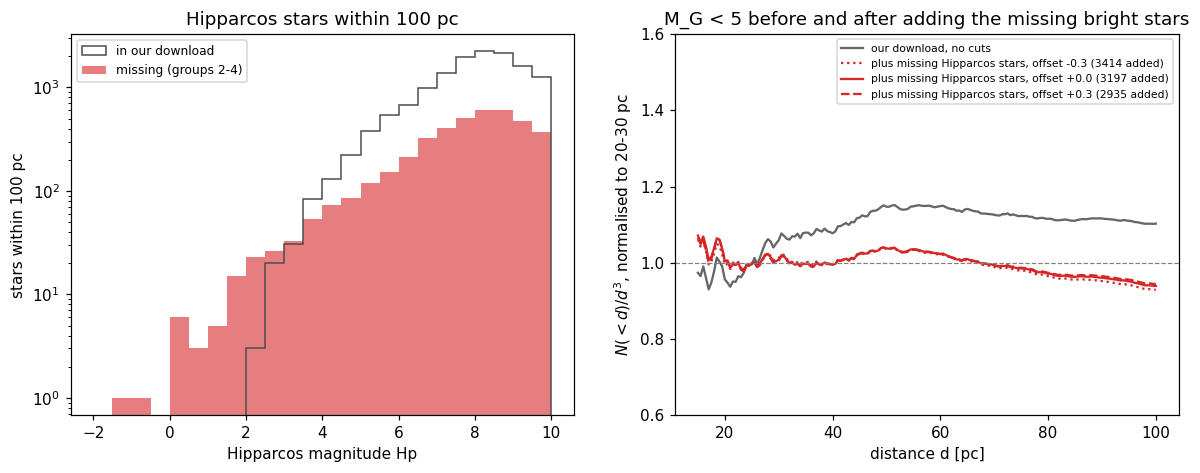

                 curve  stars added  ratio 50 pc  ratio 90 pc
 our download, no cuts            0         1.15         1.12
corrected, offset -0.3         3414         1.04         0.95
corrected, offset +0.0         3197         1.04         0.96
corrected, offset +0.3         2935         1.04         0.96


In [8]:
HP_TO_G_OFFSET = 0.0    # G ~ Hp + offset for stars without a Gaia G. Exercise: -0.3 and +0.3


def corrected_distances(offset):
    add = h[h["status"].isin(MISSING_GROUPS)].copy()
    g_est = add["g_gmag"].where(add["g_gmag"].notna(), add["hpmag"] + offset)
    add = add[(g_est + 5 * np.log10(add["plx_mas"]) - 10) < 5]
    base_d = df.loc[m_bright, "dist_pc"].to_numpy()
    return np.concatenate([base_d, add["dist_hip"].to_numpy()]), len(add)


fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
ax = axes[0]
hb = np.arange(-2, 10.01, 0.5)
ax.hist(h.loc[h["status"] == "in our download", "hpmag"], bins=hb, histtype="step", color="0.3", label="in our download")
ax.hist(h.loc[h["status"].isin(MISSING_GROUPS), "hpmag"], bins=hb, histtype="stepfilled", alpha=0.6,
        color="tab:red", label="missing (groups 2-4)")
ax.set_yscale("log"); ax.set_xlabel("Hipparcos magnitude Hp"); ax.set_ylabel("stars within 100 pc")
ax.set_title("Hipparcos stars within 100 pc"); ax.legend(fontsize=8)

ax = axes[1]
rows = []
raw_curve = completeness_curve(df.loc[m_bright, "dist_pc"])
ax.plot(D_GRID, raw_curve, color="0.4", label="our download, no cuts")
rows.append(("our download, no cuts", 0, curve_at(raw_curve, 50), curve_at(raw_curve, 90)))
for off, ls in [(HP_TO_G_OFFSET - 0.3, ":"), (HP_TO_G_OFFSET, "-"), (HP_TO_G_OFFSET + 0.3, "--")]:
    d_corr, n_add = corrected_distances(off)
    cc = completeness_curve(d_corr)
    ax.plot(D_GRID, cc, color="tab:red", ls=ls, label=f"plus missing Hipparcos stars, offset {off:+.1f} ({n_add} added)")
    rows.append((f"corrected, offset {off:+.1f}", n_add, curve_at(cc, 50), curve_at(cc, 90)))
ax.axhline(1, color="grey", lw=0.8, ls="--")
ax.set_ylim(0.6, 1.6); ax.set_xlabel("distance d [pc]"); ax.set_ylabel(r"$N(<d)/d^3$, normalised to 20-30 pc")
ax.set_title("M_G < 5 before and after adding the missing bright stars"); ax.legend(fontsize=7)
fig.savefig(FIG / "01.1_bright_limit.png")
plt.show()

print(pd.DataFrame(rows, columns=["curve", "stars added", "ratio 50 pc", "ratio 90 pc"]).to_string(
    index=False, float_format=lambda v: f"{v:.2f}"))

**How to read it.**
- *Left:* where the missing stars lie in brightness. A sharp concentration at the bright end (and none at Hp 8 to 9) is the signature of a bright limit; missing stars spread over all magnitudes would point to something else (for example binaries).
- *Right and table:* if the red curves lie on 1.0 while the grey one rises, the deficit of nearby bright stars is fully explained by stars Gaia misses. The three red line styles show how much the Hp approximation matters.

**Record your reading here:**

### 4.4 Cross-check: the GCNS list of known stars missing from Gaia

**What.** The GCNS team compiled 1258 objects with published parallax > 10 mas that are not in Gaia EDR3 or have no EDR3 parallax. We matched them to Hipparcos on the server. Here: how many have a Hipparcos counterpart, how bright these are, and which object types make up the rest.

**Why.** This is an independent list (built from SIMBAD, not from the Gaia-Hipparcos cross-match), so it checks 4.2 from a second side. The GCNS paper says some are too bright, some too faint, some binaries, and for some the reason is unclear.

**Expectation.** The members with a Hipparcos match are mostly bright (Hp < 6 to 7). The rest are mainly faint objects (brown dwarfs, white dwarfs, close binaries) that do not affect the class M_G < 5.

In [9]:
ms = missing.copy()
ms["main_id"] = ms["main_id"].astype(str).str.strip()
ms["otype"] = ms["otype"].astype(str).str.strip()
ms = ms.sort_values("sep_arcsec", na_position="last").drop_duplicates("main_id", keep="first")
ms["has_hip"] = ms["hipno"].notna()
ms["dist_pc"] = 1000.0 / ms["plx_value"]
print(f"GCNS missing-star list: {len(ms):,} objects, of which with a Hipparcos match within {MATCH_RADIUS_ARCSEC:.0f} arcsec: "
      f"{int(ms['has_hip'].sum()):,}")
print("\nThose with a Hipparcos match, by Hp:")
print(pd.cut(ms.loc[ms["has_hip"], "hpmag"], HP_BINS).value_counts().sort_index().to_string())
print("\nMost common SIMBAD object types, with and without Hipparcos match:")
print(pd.crosstab(ms["otype"], ms["has_hip"]).assign(total=lambda t: t.sum(axis=1))
      .sort_values("total", ascending=False).head(12).to_string())
both = set(ms.loc[ms["has_hip"], "hipno"].astype("int64")) & set(h.loc[h["status"].isin(MISSING_GROUPS), "hipno"])
print(f"\nHipparcos stars that are in both missing lists (4.2 and this one): {len(both):,}")

GCNS missing-star list: 1,259 objects, of which with a Hipparcos match within 60 arcsec: 858

Those with a Hipparcos match, by Hp:
hpmag
(-2, 3]     76
(3, 4]      22
(4, 5]      29
(5, 6]      51
(6, 7]      99
(7, 8]     130
(8, 9]     180
(9, 13]    267

Most common SIMBAD object types, with and without Hipparcos match:
has_hip  False  True  total
otype                      
*           42   433    475
PM          89   170    259
BD         164     9    173
            73    79    152
SB           0    92     92
LM          12     0     12
BY           0    11     11
Er           5     5     10
LP           0     7      7
a2           0     7      7
Al           0     6      6
dS           0     5      5

Hipparcos stars that are in both missing lists (4.2 and this one): 627


**How to read it.** Agreement between the two routes means the bright-star deficit is a property of Gaia, independent of how we looked for it. Many objects without a Hipparcos match is expected (Hipparcos does not reach faint stars), but they should be types that are faint (for example `BD*` brown dwarfs, `WD*` white dwarfs) or doubles.

**Record your reading here:**

### 4.5 Local structures (H3) and north versus south (H4)

**What.** Repeat the curve without cuts (i) after removing all GCNS cluster candidates (Hyades and Coma Ber, `gcns.hyacob`), (ii) for the northern (b > 0) and southern (b < 0) Galactic hemispheres separately.

**Predictions.** H3: removing the clusters changes the values at 50 and 90 pc by less than about 0.02. H4: a real density gradient would make the curve *fall* with distance; the Sun sits slightly north of the mid-plane, so a gradient would also differ between north and south. If both hemispheres rise in the same way, a geometric density effect is unlikely.

In [10]:
cluster_ids = set(hyacob["source_id"])
rows = []
for name, sel in [("no cuts, all", m_bright),
                  ("no cuts, without GCNS cluster candidates", m_bright & ~df["source_id"].isin(cluster_ids)),
                  ("no cuts, north (b > 0)", m_bright & (df["b"] > 0)),
                  ("no cuts, south (b < 0)", m_bright & (df["b"] < 0))]:
    c = completeness_curve(df.loc[sel, "dist_pc"])
    rows.append((name, int(sel.sum()), curve_at(c, 50), curve_at(c, 90)))
print(pd.DataFrame(rows, columns=["sample", "n", "ratio 50 pc", "ratio 90 pc"]).to_string(
    index=False, float_format=lambda v: f"{v:.2f}"))
print(f"\nCluster candidates removed from the class: {int((m_bright & df['source_id'].isin(cluster_ids)).sum())}")

                                  sample     n  ratio 50 pc  ratio 90 pc
                            no cuts, all 21475         1.15         1.12
no cuts, without GCNS cluster candidates 21339         1.12         1.11
                  no cuts, north (b > 0) 10616         1.10         1.12
                  no cuts, south (b < 0) 10859         1.19         1.11

Cluster candidates removed from the class: 136


**How to read it.** Compare each row with the first. Small differences rule out H3 as the cause. Two hemispheres that rise alike argue against H4. Remember that each hemisphere has only half the stars, so its normalisation is noisier (about 1.4 times the bootstrap interval of 4.1).

**Record your reading here:**

## 5. Question 2: how good was the Hyades window search?

**Recap.** Section 8.3 of notebook 01 found 285 stars inside a proper-motion circle of 25 mas/yr, with about 54 field stars expected from a ring around the circle, so an estimated purity of about 80 %. The centre (l = 180°, b = -22.4°) and proper motion (101, -28) mas/yr were from memory.

**What changes now.** The centre comes from Röser et al. 2019 (Eq. 1: X, Y, Z = -44.77, +0.40, -16.24 pc, converted below to l, b, distance) and the proper motion from Babusiaux et al. 2018 (Table A.3: 101.005, -28.490 mas/yr). Then our candidates are matched *by source_id* with two published member lists that use DR3 identifiers: the GCNS Hyades candidates (`gcns.hyacob`, 920 stars, including tidal tails; 630 lie within 20 pc of the centre) and Hunt & Reffert 2024.

**Two measures.** *Purity* = share of our candidates that are in the list. *Recall* = share of the list that we found. Recall is reported at four levels, so that losses from our quality cuts are separated from losses from the window method itself:

| Level | Denominator: list members that are ... |
|---|---|
| all | in the list |
| in download | in our download (parallax ≥ 10 mas, parallax_over_error ≥ 10) |
| clean | in our cleaned sample |
| in window | in our cleaned sample *and* inside the sky and distance window |

**Competing hypotheses for the purity.**

| Hypothesis | Prediction |
|---|---|
| a: the ring estimate (about 80 %) is right | purity against the GCNS list close to 0.8 |
| b: the ring underestimates the field (field stars are not evenly spread in proper motion) | purity clearly below 0.8; the stars found only by us lie off the Hyades sequence in the HRD, like field stars |
| c: the published lists are incomplete inside our window | the stars found only by us lie *on* the Hyades sequence; then the true purity is higher than the matched value |

**Expectation for the recall.** Most losses come from the RUWE cut (binaries) and, for stars far from the centre, from the proper-motion circle (perspective changes the proper motion across the cluster).

**Analogy.** Validating a population-assignment method against a curated reference panel: precision and recall, with the caveat that the reference panel itself has errors.

In [11]:
ROESER_XYZ = (-44.77, 0.40, -16.24)     # pc, Hyades centre, Röser et al. 2019 Eq. 1 (Galactic Cartesian, X to the Galactic centre)
BABUSIAUX_PM = (101.005, -28.490)       # mas/yr, Hyades proper motion, Babusiaux et al. 2018 Table A.3
OLD_CENTRE = (180.0, -22.4)             # notebook 01, from memory
HY_RADIUS_DEG = 25.0                    # sky window radius. Exercise: 10 or 40
HY_DIST = (35.0, 60.0)                  # distance window [pc]
PM_RADIUS = 25.0                        # proper-motion circle [mas/yr]. Exercise: 15 or 35

X, Y, Z = ROESER_XYZ                    # Galactic Cartesian to Galactic longitude, latitude and distance
HY_D = float(np.sqrt(X**2 + Y**2 + Z**2))
HY_L = float(np.degrees(np.arctan2(Y, X)) % 360)
HY_B = float(np.degrees(np.arcsin(Z / HY_D)))
print(f"Röser et al. 2019 centre: l = {HY_L:.2f} deg, b = {HY_B:.2f} deg, distance = {HY_D:.2f} pc")
print(f"Offset of the notebook 01 centre: {angsep_deg(OLD_CENTRE[0], OLD_CENTRE[1], HY_L, HY_B):.2f} deg")


def window_search(data, l0, b0, pm0=BABUSIAUX_PM):
    sep = angsep_deg(data["l"].to_numpy(), data["b"].to_numpy(), l0, b0)
    sky = sep < HY_RADIUS_DEG
    dist = data["dist_pc"].between(*HY_DIST).to_numpy()
    dpm = np.hypot(data["pmra"].to_numpy() - pm0[0], data["pmdec"].to_numpy() - pm0[1])
    ring_lo, ring_hi = 1.6 * PM_RADIUS, 2.6 * PM_RADIUS
    out = pd.DataFrame({"sky": sky, "dist": dist, "dpm": dpm, "sep": sep}, index=data.index)
    out["win"] = sky & dist
    out["cand"] = out["win"] & (dpm < PM_RADIUS)
    out["ring"] = out["win"] & (dpm >= ring_lo) & (dpm < ring_hi)
    bg = out["ring"].sum() / ((ring_hi**2 - ring_lo**2) / PM_RADIUS**2)
    return out, bg


rows = []
searches = {}
for name, data, l0, b0 in [("notebook 01 centre, clean sample", df[df["clean"]], *OLD_CENTRE),
                           ("Röser centre, clean sample", df[df["clean"]], HY_L, HY_B),
                           ("Röser centre, no cuts", df, HY_L, HY_B)]:
    w, bg = window_search(data, l0, b0)
    searches[name] = w
    n = int(w["cand"].sum())
    c = data.loc[w["cand"]]
    rows.append((name, int(w["win"].sum()), n, bg, (n - bg) / max(n, 1), c["dist_pc"].median(),
                 c["pmra"].median(), c["pmdec"].median()))
print(pd.DataFrame(rows, columns=["search", "in window", "in PM circle", "field (ring)", "ring purity",
                                  "median d [pc]", "median pmra", "median pmdec"]).to_string(
    index=False, float_format=lambda v: f"{v:.2f}"))

Röser et al. 2019 centre: l = 179.49 deg, b = -19.94 deg, distance = 47.63 pc
Offset of the notebook 01 centre: 2.51 deg
                          search  in window  in PM circle  field (ring)  ring purity  median d [pc]  median pmra  median pmdec
notebook 01 centre, clean sample       2053           288         54.52         0.81          47.45       103.85        -27.36
      Röser centre, clean sample       2056           284         53.57         0.81          47.42       103.64        -27.31
           Röser centre, no cuts       3173           466         85.24         0.82          47.57       102.41        -27.59


**How to read it.** The first row should reproduce notebook 01 (285 candidates, about 54 field stars). The second row is the same search around the literature centre. The third row is without any quality cut: the difference between rows 2 and 3 is what our cuts remove inside the cluster.

**Record your reading here:**

In [12]:
CORE_PC = 20.0      # "core" = GCNS candidates within this distance of the cluster barycentre (GCNS: two tidal radii = 20 pc)

hy = hyacob[hyacob["name"].astype(str).str.contains("hya", case=False)].copy()
truth = {"GCNS Hyades, all (incl. tails)": set(hy["source_id"]),
         f"GCNS Hyades, within {CORE_PC:.0f} pc of centre": set(hy.loc[hy["dist_cluster"] <= CORE_PC, "source_id"])}
if hr is not None:
    truth["Hunt & Reffert 2024, all"] = set(hr["source_id"])
    if "hr_in_rt" in hr:
        truth["Hunt & Reffert 2024, inside r_t"] = set(hr.loc[hr["hr_in_rt"], "source_id"])
for k, v in truth.items():
    print(f"{k:45s} {len(v):5d} stars")

clean_df = df[df["clean"]]
w = searches["Röser centre, clean sample"]
cand_ids = set(clean_df.loc[w["cand"], "source_id"])
win_ids = set(clean_df.loc[w["win"], "source_id"])
ids_dl, ids_clean = set(df["source_id"]), set(clean_df["source_id"])
bg = searches["Röser centre, clean sample"]["ring"].sum() / ((2.6**2 - 1.6**2))

rows = []
for name, T in truth.items():
    both = cand_ids & T
    rows.append((name, len(cand_ids), len(both), len(both) / max(len(cand_ids), 1),
                 len(both) / max(len(T), 1), len(both) / max(len(T & ids_dl), 1),
                 len(both) / max(len(T & ids_clean), 1), len(both) / max(len(T & win_ids), 1)))
q2 = pd.DataFrame(rows, columns=["reference list", "our candidates", "in both", "purity",
                                 "recall: all", "recall: in download", "recall: clean", "recall: in window"])
print("\nOur candidates (Röser centre, clean sample) against the reference lists:")
print(q2.to_string(index=False, float_format=lambda v: f"{v:.2f}"))
print(f"Ring estimate of the purity, for comparison: {(len(cand_ids) - bg) / max(len(cand_ids), 1):.2f}")

# Where are the members we do not find? Each member is assigned to the first step that loses it.
gidx = gcns.set_index("source_id")
dfi = df.set_index("source_id")
sky_all = angsep_deg(dfi["l"].to_numpy(), dfi["b"].to_numpy(), HY_L, HY_B) < HY_RADIUS_DEG
dfi["in_sky"] = sky_all
dfi["in_dist"] = dfi["dist_pc"].between(*HY_DIST)
dfi["in_pm"] = np.hypot(dfi["pmra"] - BABUSIAUX_PM[0], dfi["pmdec"] - BABUSIAUX_PM[1]) < PM_RADIUS


def lost_at(sid):
    if sid not in dfi.index:
        if sid in gidx.index and (gidx.at[sid, "parallax"] / gidx.at[sid, "parallax_error"] < 10):
            return "1 not downloaded: parallax_over_error < 10"
        if sid in gidx.index and gidx.at[sid, "parallax"] < 10:
            return "1 not downloaded: parallax < 10 mas"
        return "1 not downloaded: other reason"
    r = dfi.loc[sid]
    if not r["ok_ruwe"]:
        return "2 removed by RUWE"
    if not r["other"]:
        return "3 removed by photometric cuts"
    if not r["in_sky"]:
        return "4 outside the sky window"
    if not r["in_dist"]:
        return "5 outside the distance window"
    if not r["in_pm"]:
        return "6 outside the proper-motion circle"
    return "7 found"


funnel = pd.DataFrame({name: pd.Series([lost_at(s) for s in T]).value_counts() for name, T in truth.items()}).fillna(0).astype(int)
print("\nWhere the reference members end up (first step that loses them):")
print(funnel.sort_index().to_string())

GCNS Hyades, all (incl. tails)                  920 stars
GCNS Hyades, within 20 pc of centre             630 stars
Hunt & Reffert 2024, all                        927 stars
Hunt & Reffert 2024, inside r_t                 386 stars

Our candidates (Röser centre, clean sample) against the reference lists:
                     reference list  our candidates  in both  purity  recall: all  recall: in download  recall: clean  recall: in window
     GCNS Hyades, all (incl. tails)             284      236    0.83         0.26                 0.26           0.38               0.58
GCNS Hyades, within 20 pc of centre             284      236    0.83         0.37                 0.37           0.55               0.59
           Hunt & Reffert 2024, all             284      241    0.85         0.26                 0.26           0.41               0.58
    Hunt & Reffert 2024, inside r_t             284      215    0.76         0.56                 0.56           0.83               0.83
Ring esti

**How to read it.**
- *Purity column:* compare with the ring estimate printed below the table. Purity against the full GCNS list (with tails) is the fairest number, because our window reaches beyond the core.
- *Recall columns, left to right:* each step removes one cause of loss. A big jump from "all" to "in download" means many members are faint (parallax_over_error < 10); a jump from "in download" to "clean" means our quality cuts remove members; "in window" is the performance of the window method itself.
- *Funnel:* the same story member by member. Expect step 2 (RUWE) to be large, because the Hyades have many binaries, and step 6 to contain mostly members far from the centre.

**Record your reading here:**

                     group   n  on the Hyades sequence [%]  median |dM_G| [mag]  with Gaia RV  RV agrees with cluster motion [%]  median offset from PM centre [mas/yr]  median distance [pc]
                      both 236                        97.0                  0.1           169                               98.2                                   14.5                  47.2
                 only ours  48                        47.9                  0.3            33                               15.2                                   17.3                  49.8
           only literature 173                        91.9                  0.1           111                               95.5                                   40.3                  46.0
field (proper-motion ring) 225                        61.2                  0.2           160                               36.2                                   52.7                  50.9


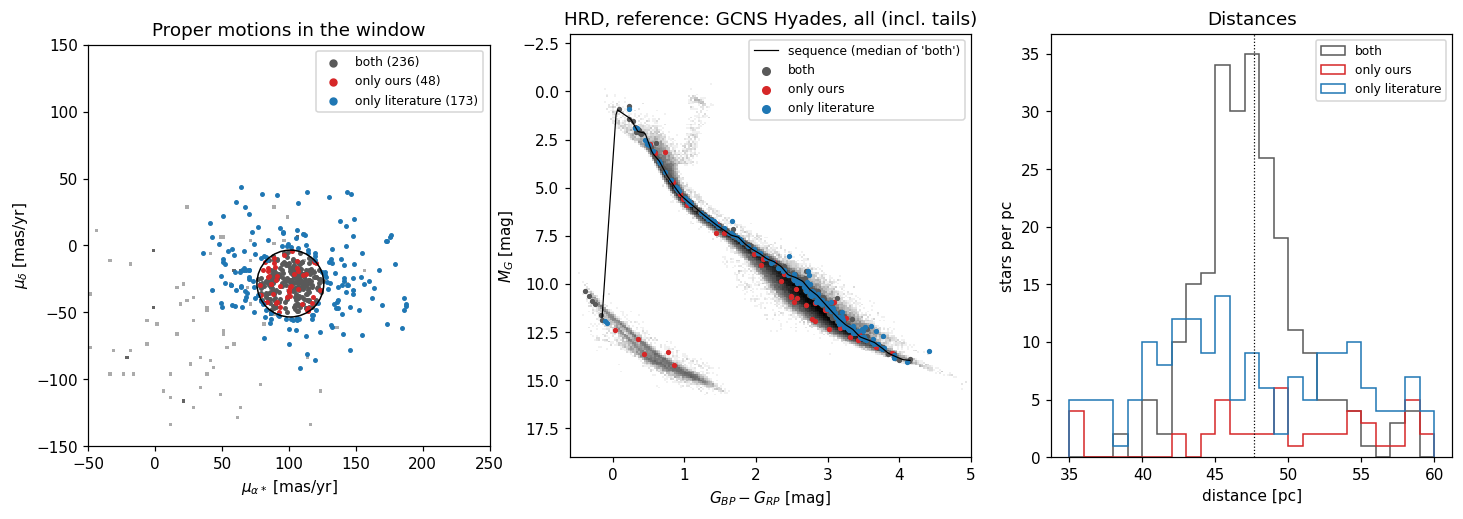

In [13]:
MAIN_TRUTH = "GCNS Hyades, all (incl. tails)"     # which list defines the colours in the figure
SEQ_BRIGHT, SEQ_FAINT = 0.8, 0.25                 # "on the sequence" = up to 0.8 mag brighter (binaries) or 0.25 mag fainter
ROESER_UVW = (-42.24, -19.00, -1.48)              # km/s, Hyades space velocity, Röser et al. 2019 Eq. 1
RV_TOL = 2.0                                      # km/s; a star "agrees" if |RV - predicted| < max(RV_TOL, 3 x RV error)

T = truth[MAIN_TRUTH]
win_df = clean_df.loc[w["win"]].copy()
win_df["cand"] = w.loc[w["win"], "cand"].to_numpy()
win_df["ring"] = w.loc[w["win"], "ring"].to_numpy()
win_df["lit"] = win_df["source_id"].isin(T)
win_df["dpm"] = w.loc[w["win"], "dpm"].to_numpy()
groups ={"both": win_df["cand"] & win_df["lit"], "only ours": win_df["cand"] & ~win_df["lit"],
          "only literature": ~win_df["cand"] & win_df["lit"]}

# Empirical Hyades sequence from the stars found by both: running median of M_G in colour bins of 0.1 mag
b_ = win_df[groups["both"]]
edges = np.arange(-0.2, 5.01, 0.1)
med = b_.groupby(pd.cut(b_["bp_rp"], edges), observed=False)["mg"].median()
centres = 0.5 * (edges[:-1] + edges[1:])
ok = med.notna().to_numpy()
seq = lambda x: np.interp(x, centres[ok], med.to_numpy()[ok], left=np.nan, right=np.nan)
win_df["dmg"] = win_df["mg"] - seq(win_df["bp_rp"].to_numpy())
on_seq = (win_df["dmg"] > -SEQ_BRIGHT) & (win_df["dmg"] < SEQ_FAINT)

# Radial velocity predicted for a cluster member at each star's position: projection of the cluster velocity on the line of sight
lr, br = np.radians(win_df["l"].to_numpy()), np.radians(win_df["b"].to_numpy())
rhat = np.c_[np.cos(br) * np.cos(lr), np.cos(br) * np.sin(lr), np.sin(br)]
win_df["rv_pred"] = rhat @ np.array(ROESER_UVW)
has_rv = win_df["radial_velocity"].notna()
tol = np.maximum(RV_TOL, 3 * win_df["radial_velocity_error"].fillna(0))
rv_ok = (win_df["radial_velocity"] - win_df["rv_pred"]).abs() < tol

rows = []
for name, g in list(groups.items()) + [("field (proper-motion ring)", win_df["ring"])]:
    s = win_df[g & win_df["dmg"].notna()]
    r = g & has_rv
    rows.append((name, int(g.sum()), 100 * on_seq[s.index].mean() if len(s) else np.nan,
                 s["dmg"].abs().median() if len(s) else np.nan, int(r.sum()),
                 100 * rv_ok[r].mean() if r.sum() else np.nan,
                 win_df.loc[g, "dpm"].median(), win_df.loc[g, "dist_pc"].median()))
print(pd.DataFrame(rows, columns=["group", "n", "on the Hyades sequence [%]", "median |dM_G| [mag]", "with Gaia RV",
                                  "RV agrees with cluster motion [%]", "median offset from PM centre [mas/yr]",
                                  "median distance [pc]"]).to_string(index=False, float_format=lambda v: f"{v:.1f}"))

colors = {"both": "0.35", "only ours": "tab:red", "only literature": "tab:blue"}
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
ax = axes[0]
ax.hist2d(win_df["pmra"], win_df["pmdec"], bins=120, range=((-50, 250), (-150, 150)), norm=LogNorm(), cmap="Greys", cmin=1)
for name, g in groups.items():
    ax.scatter(win_df.loc[g, "pmra"], win_df.loc[g, "pmdec"], s=5, color=colors[name], label=f"{name} ({int(g.sum())})")
ax.add_patch(plt.Circle(BABUSIAUX_PM, PM_RADIUS, fill=False, ec="k", lw=1))
ax.set_aspect("equal"); ax.set_xlabel(r"$\mu_{\alpha*}$ [mas/yr]"); ax.set_ylabel(r"$\mu_\delta$ [mas/yr]")
ax.set_title("Proper motions in the window"); ax.legend(fontsize=8, markerscale=2)
ax = axes[1]
okc = clean_df["bp_rp"].notna()
ax.hist2d(clean_df.loc[okc, "bp_rp"], clean_df.loc[okc, "mg"], bins=(200, 240), range=((-0.6, 5), (-3, 19)),
          norm=LogNorm(), cmap="Greys", cmin=1)
xs = np.linspace(centres[ok].min(), centres[ok].max(), 200)
ax.plot(xs, seq(xs), color="k", lw=0.8, label="sequence (median of 'both')")
for name, g in groups.items():
    ax.scatter(win_df.loc[g, "bp_rp"], win_df.loc[g, "mg"], s=6, color=colors[name], label=name)
ax.set_ylim(19, -3); ax.set_xlabel(r"$G_{BP}-G_{RP}$ [mag]"); ax.set_ylabel(r"$M_G$ [mag]")
ax.set_title(f"HRD, reference: {MAIN_TRUTH}"); ax.legend(fontsize=8, markerscale=2)
ax = axes[2]
bins = np.arange(HY_DIST[0], HY_DIST[1] + 1, 1.0)
for name, g in groups.items():
    ax.hist(win_df.loc[g, "dist_pc"], bins=bins, histtype="step", color=colors[name], label=name)
ax.axvline(HY_D, color="k", lw=0.8, ls=":")
ax.set_xlabel("distance [pc]"); ax.set_ylabel("stars per pc"); ax.set_title("Distances"); ax.legend(fontsize=8)
fig.savefig(FIG / "01.1_hyades_validation.png")
plt.show()

**How to read it.**
- *Table, two independent tests:* (1) "on the Hyades sequence" and "median |dM_G|": the Hyades sequence is narrow, the field main sequence is broad (different ages and metallicities), so field stars sit on it less often and farther from it. (2) "RV agrees with cluster motion": the cluster's space velocity (Röser et al. 2019) predicts the radial velocity a member must have at its position. Our selection never used radial velocities, so this is a test the window search could not have tuned itself to. Only bright stars have Gaia RVs, so the counts are smaller. Field stars in the proper-motion ring give the baseline for chance agreement. If "only ours" behaves like "both", our extra stars are probably real members missing from the list (hypothesis c). If it behaves like the field, they are contaminants (hypothesis b).
- *Left:* "only literature" stars outside the black circle are members whose proper motion differs by more than 25 mas/yr from the centre value, mostly because of perspective.
- *Middle:* the thin black line is the empirical sequence. Binaries lie up to 0.75 mag above it.
- *Right:* all groups should peak near the dotted line (centre distance from Röser et al.).

**Record your reading here:**

## 6. Question 3: our cleaned sample against the GCNS

**What.** The GCNS is the reference catalogue of the 100 pc volume, built from the same Gaia data with a machine-learning filter for spurious solutions instead of hard cuts. Per brightness class: how many GCNS stars with parallax ≥ 10 mas are in our download and in our cleaned sample, and which step loses the rest. Then the reverse: which of our sources are not in the GCNS at all.

**Why the denominator matters.** The GCNS keeps every object with a non-zero chance of lying within 100 pc; 300 526 have a median distance below 100 pc (Smart et al. 2021). Notebook 01 compared with all 331 312, which makes our share look too small. Here the denominator is GCNS stars with parallax ≥ 10 mas, the same definition as our download. The GCNS has no parallax_over_error cut, so faint stars missing from our download are expected.

**Predictions.**
- M_G > 13: losses dominated by parallax_over_error < 10 and by the BP/RP S/N cut.
- M_G 5 to 13: losses dominated by RUWE.
- Our sources that are not in the GCNS: concentrated at low Galactic latitude and mostly failing our colour cuts, like the box sources of section 8.2 in notebook 01 (spurious solutions that the GCNS filter rejected).
- **Link to question 1:** the GCNS curve of the class M_G < 5 should rise like ours, because it is built from the same Gaia data with the same bright limit. If it does not rise, our cuts or download would be the cause.

**Analogy.** Comparing a hard-filter QC pipeline with a trained classifier on the same reads: overlap, what each keeps that the other drops, and why.

In [14]:
g = gcns.copy()
g["mg"] = absolute_mag(g["phot_g_mean_mag"], g["parallax"])
g["bp_rp"] = g["phot_bp_mean_mag"] - g["phot_rp_mean_mag"]
g["poe"] = g["parallax"] / g["parallax_error"]
g100 = g[g["parallax"] >= 10].copy()
print(f"GCNS objects: {len(g):,}; with parallax >= 10 mas: {len(g100):,}; with dist_50 < 0.1 kpc: {int((g['dist_50'] < 0.1).sum()):,}")

flags = df.set_index("source_id")[["ok_ruwe", "ok_g", "ok_bprp", "ok_cstar", "clean"]]
g100 = g100.join(flags, on="source_id")
g100["in_dl"] = g100["clean"].notna()

stages = []
for lo, hi, label in CLASSES + [(-99, 99, "all classes")]:
    s = g100[in_class(g100["mg"], lo, hi)]
    n = len(s)
    nd = ~s["in_dl"]
    dl = s[s["in_dl"]]
    r1 = ~dl["ok_ruwe"].astype(bool)
    r2 = ~r1 & ~dl["ok_g"].astype(bool)
    r3 = ~r1 & ~r2 & ~dl["ok_bprp"].astype(bool)
    r4 = ~r1 & ~r2 & ~r3 & ~dl["ok_cstar"].astype(bool)
    stages.append(dict(**{"class": label, "GCNS (plx >= 10)": n,
                          "not downloaded: poe < 10 [%]": 100 * (nd & (s["poe"] < 10)).sum() / n,
                          "not downloaded: other [%]": 100 * (nd & ~(s["poe"] < 10)).sum() / n,
                          "removed RUWE [%]": 100 * r1.sum() / n, "removed G S/N [%]": 100 * r2.sum() / n,
                          "removed BP/RP S/N [%]": 100 * r3.sum() / n, "removed C* [%]": 100 * r4.sum() / n,
                          "kept (clean) [%]": 100 * dl["clean"].astype(bool).sum() / n}))
print("\nGCNS stars with parallax >= 10 mas: what happens to them in our pipeline (each star counted at the first step that removes it)")
print(pd.DataFrame(stages).to_string(index=False, float_format=lambda v: f"{v:.1f}"))

GCNS objects: 331,312; with parallax >= 10 mas: 302,197; with dist_50 < 0.1 kpc: 300,526

GCNS stars with parallax >= 10 mas: what happens to them in our pipeline (each star counted at the first step that removes it)
      class  GCNS (plx >= 10)  not downloaded: poe < 10 [%]  not downloaded: other [%]  removed RUWE [%]  removed G S/N [%]  removed BP/RP S/N [%]  removed C* [%]  kept (clean) [%]
    M_G < 5             21474                           0.0                        0.0              24.9                0.0                    0.3             3.1              71.7
   M_G 5-10             98008                           0.0                        0.0              26.5                0.0                    1.1             3.0              69.4
  M_G 10-13            129509                           0.0                        0.0              12.8                0.0                    4.3             3.2              79.7
   M_G > 13             52896                           2.6

In [15]:
in_g = df["source_id"].isin(g["source_id"])
rows = []
for lo, hi, label in CLASSES + [(-99, 99, "all classes")]:
    sel = in_class(df["mg"], lo, hi) & ~in_g
    s = df[sel]
    rows.append((label, len(s), 100 * (s["b"].abs() < 15).mean() if len(s) else np.nan,
                 100 * (~s["other"]).mean() if len(s) else np.nan, 100 * s["fail_ruwe"].mean() if len(s) else np.nan,
                 int(s["clean"].sum())))
print("Our downloaded sources that are not in the GCNS at all:")
print(pd.DataFrame(rows, columns=["class", "n", "|b| < 15 deg [%]", "fail photometric cuts [%]", "fail RUWE [%]",
                                  "still in our clean sample"]).to_string(index=False, float_format=lambda v: f"{v:.1f}"))
print("Uniform sky would give 25.9 % at |b| < 15 deg.")

Our downloaded sources that are not in the GCNS at all:
      class     n  |b| < 15 deg [%]  fail photometric cuts [%]  fail RUWE [%]  still in our clean sample
    M_G < 5     1             100.0                      100.0          100.0                          0
   M_G 5-10    68              55.9                       86.8          100.0                          0
  M_G 10-13  1021              74.6                       97.4           99.6                          0
   M_G > 13 70150              96.6                       99.6           77.5                         18
all classes 71240              96.2                       99.5           77.8                         18
Uniform sky would give 25.9 % at |b| < 15 deg.


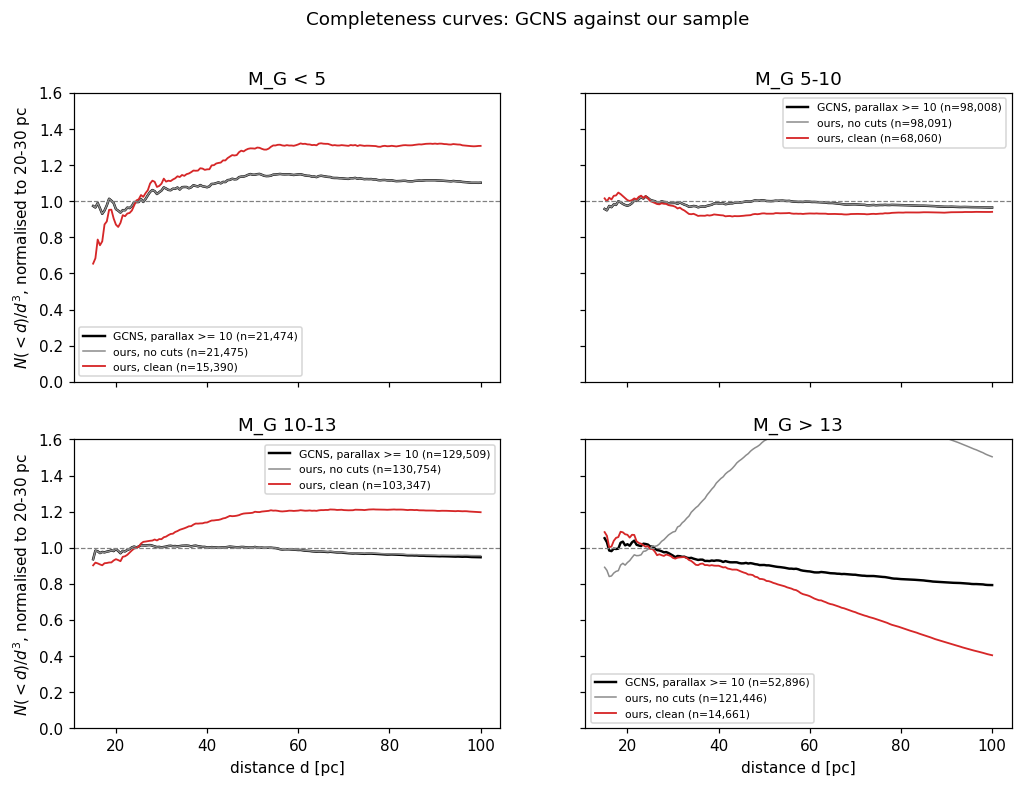

    class               sample      n  ratio 50 pc  ratio 90 pc
  M_G < 5 GCNS, parallax >= 10  21474         1.15         1.12
  M_G < 5        ours, no cuts  21475         1.15         1.12
  M_G < 5          ours, clean  15390         1.29         1.32
 M_G 5-10 GCNS, parallax >= 10  98008         1.00         0.97
 M_G 5-10        ours, no cuts  98091         1.00         0.97
 M_G 5-10          ours, clean  68060         0.93         0.94
M_G 10-13 GCNS, parallax >= 10 129509         1.00         0.95
M_G 10-13        ours, no cuts 130754         1.00         0.96
M_G 10-13          ours, clean 103347         1.19         1.21
 M_G > 13 GCNS, parallax >= 10  52896         0.90         0.81
 M_G > 13        ours, no cuts 121446         1.59         1.61
 M_G > 13          ours, clean  14661         0.82         0.47


In [16]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7.5), sharex=True, sharey=True)
rows = []
for ax, (lo, hi, label) in zip(axes.ravel(), CLASSES):
    for name, dist, kw in [
            ("GCNS, parallax >= 10", 1000 / g100.loc[in_class(g100["mg"], lo, hi), "parallax"], dict(color="k", lw=1.6)),
            ("ours, no cuts", df.loc[in_class(df["mg"], lo, hi), "dist_pc"], dict(color="0.55", lw=1.0)),
            ("ours, clean", df.loc[in_class(df["mg"], lo, hi) & df["clean"], "dist_pc"], dict(color="tab:red", lw=1.2))]:
        c = completeness_curve(dist)
        ax.plot(D_GRID, c, label=f"{name} (n={len(dist):,})", **kw)
        rows.append((label, name, len(dist), curve_at(c, 50), curve_at(c, 90)))
    ax.axhline(1, color="grey", lw=0.8, ls="--"); ax.set_title(label); ax.set_ylim(0, 1.6); ax.legend(fontsize=7)
for ax in axes[1]:
    ax.set_xlabel("distance d [pc]")
for ax in axes[:, 0]:
    ax.set_ylabel(r"$N(<d)/d^3$, normalised to 20-30 pc")
fig.suptitle("Completeness curves: GCNS against our sample")
fig.savefig(FIG / "01.1_gcns_comparison.png")
plt.show()
print(pd.DataFrame(rows, columns=["class", "sample", "n", "ratio 50 pc", "ratio 90 pc"]).to_string(
    index=False, float_format=lambda v: f"{v:.2f}"))

**How to read it.**
- *First table:* row "all classes", last column, is the true share of the 100 pc volume (as defined by the GCNS) that our cleaned sample keeps. It replaces the "about 60 %" of notebook 01. The columns in between show where each class loses its stars. "not downloaded: other" should be close to zero; a large value would mean the two catalogues disagree on parallax or precision for the same source.
- *Second table:* sources only we have. A strong concentration at low |b| and a high failure rate in the photometric cuts mean they are spurious solutions that both pipelines reject. The last column counts those that survive our cuts but not the GCNS filter: these would be the contamination of our clean sample.
- *Figure:* black is the GCNS. For M_G < 5, a rising black curve shows that the deficit of nearby bright stars is in Gaia itself (supports question 1, H1). For M_G > 13, the gap between black and red is what our cuts and the parallax_over_error ≥ 10 condition cost.

**Record your reading here:**

## 7. Question 4: why is RUWE failure highest at 30 to 50 pc for M_G 5 to 10?

**Recap.** Share of stars with RUWE ≥ 1.4 (photometric cuts applied) for M_G 5 to 10: 18.0 % at 15 to 30 pc, **24.2 %** at 30 to 50 pc, 20.7 % at 50 to 75 pc, 18.2 % at 75 to 100 pc. A simple test-power argument predicts a monotonic fall with distance, as seen for M_G 10 to 13.

**Background (literature, Section 8.4 of `literature.md`).** High RUWE has two binary regimes: (1) the light centre wobbles on an unresolved orbit (periods of about 100 to 5000 days); (2) the pair is *marginally resolved*: Gaia sees two blurred peaks and the measured position follows neither star (El-Badry 2025). Fully resolved pairs (more than about 0.7 arcsec apart) are measured as two separate sources and need not have high RUWE. The angle of a pair is separation in au divided by distance in pc. Solar-type binaries peak near 50 au (Raghavan et al. 2010), M dwarf companions at 4 to 20 au (Winters et al. 2019).

**Competing hypotheses.**

| Hypothesis | Test | Supported if | Refuted if |
|---|---|---|---|
| A Hyades | remove GCNS Hyades candidates; remove the whole Hyades sky window | the 30-50 pc value drops to the level of its neighbours | it hardly changes. Expected, because the class has about 8000 stars at 30 to 50 pc and the Hyades contribute at most a few hundred: even if all failed, the rate would move by 2 to 3 points |
| B resolved versus unresolved pairs (your hypothesis) | search pairs inside our download; share of stars with a resolved companion versus distance; RUWE failure versus angular separation | the share of stars with a resolved companion falls with distance, and stars with a close companion fail RUWE more often | no trend, or no excess failure at small separations |
| B' marginally resolved pairs | RUWE failures split by `ipd_frac_multi_peak` (fraction of Gaia image windows with a double peak, from the GCNS) | the excess at 30 to 50 pc is carried by sources with double peaks; among sources without double peaks the rate falls smoothly with distance | the excess is the same with and without double peaks |
| D interplay with the colour cuts | failure rates without the photometric cuts | the maximum disappears or moves: the colour cuts had removed close pairs at some distances before RUWE could count them | the pattern is unchanged |
| E chance | 95 % binomial intervals | intervals of neighbouring bins overlap | they do not (expected: about ± 1 point at n ≈ 8000) |

My reasoning, not a literature result: for each class the RUWE failure rate should be highest at the distance where its typical binary separation appears at about 0.1 to 0.7 arcsec. For M dwarfs (4 to 20 au) that is within about 30 pc, for K and early M stars somewhat farther, for solar-type stars (about 50 au) beyond 70 pc. Section 7.4 shows the numbers.

baseline: photometric cuts (as notebook 01)
    class                 15-30 pc                  30-50 pc                  50-75 pc                 75-100 pc
  M_G < 5   24.7 [20.9,29.0] n=429   21.8 [20.0,23.6] n=1986   21.9 [20.9,23.0] n=5885  21.3 [20.6,22.1] n=11299
 M_G 5-10  18.0 [16.4,19.8] n=2018   24.2 [23.4,25.2] n=8621  20.7 [20.2,21.2] n=25160  18.2 [17.8,18.5] n=48477
M_G 10-13  20.6 [19.1,22.2] n=2745  10.3 [ 9.8,10.9] n=11646   7.4 [ 7.1, 7.7] n=33693   5.1 [ 5.0, 5.3] n=62462
 M_G > 13    7.8 [ 6.2, 9.8] n=858    4.0 [ 3.4, 4.8] n=2928    3.2 [ 2.7, 3.6] n=5634    3.6 [ 3.1, 4.1] n=5675

A1: without GCNS Hyades candidates
    class                 15-30 pc                  30-50 pc                  50-75 pc                 75-100 pc
  M_G < 5   24.7 [20.9,29.0] n=429   21.6 [19.8,23.5] n=1919   21.9 [20.9,23.0] n=5866  21.3 [20.6,22.1] n=11295
 M_G 5-10  18.0 [16.4,19.8] n=2014   24.3 [23.4,25.2] n=8472  20.7 [20.2,21.2] n=25085  18.2 [17.8,18.5] n=48460
M_G 10-13  20.5 

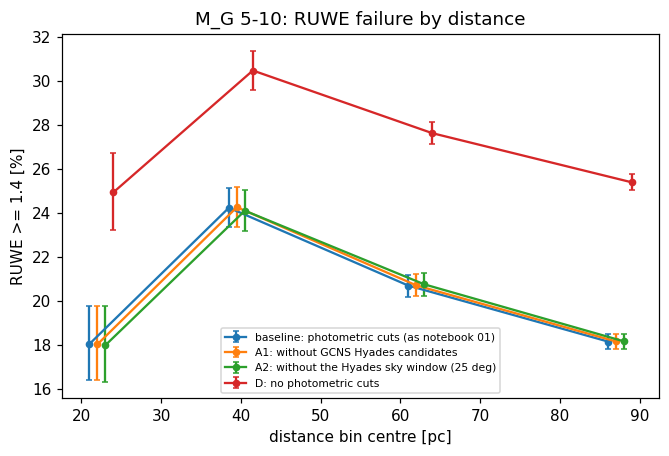

In [17]:
def fail_table(sample, title, verbose=True):
    """RUWE >= 1.4 share per class and distance bin, with 95 % intervals. Returns numbers for plotting."""
    rows, num = [], []
    for lo, hi, label in CLASSES:
        row = {"class": label}
        for d0, d1 in zip(DBINS[:-1], DBINS[1:]):
            m = sample & in_class(df["mg"], lo, hi) & (df["dist_pc"] >= d0) & (df["dist_pc"] < d1)
            n, k = int(m.sum()), int((df.loc[m, "fail_ruwe"]).sum())
            p, a, b = wilson(k, n)
            row[f"{d0}-{d1} pc"] = f"{p:5.1f} [{a:4.1f},{b:4.1f}] n={n}" if n >= 30 else "-"
            num.append((label, d0, d1, n, p, a, b))
        rows.append(row)
    if verbose:
        print(title)
        print(pd.DataFrame(rows).to_string(index=False))
        print()
    return pd.DataFrame(num, columns=["class", "d0", "d1", "n", "p", "lo", "hi"])


hy_ids = set(hyacob.loc[hyacob["name"].astype(str).str.contains("hya", case=False), "source_id"])
outside_window = angsep_deg(df["l"].to_numpy(), df["b"].to_numpy(), HY_L, HY_B) >= HY_RADIUS_DEG
variants = {
    "baseline: photometric cuts (as notebook 01)": df["other"],
    "A1: without GCNS Hyades candidates": df["other"] & ~df["source_id"].isin(hy_ids),
    f"A2: without the Hyades sky window ({HY_RADIUS_DEG:.0f} deg)": df["other"] & outside_window,
    "D: no photometric cuts": pd.Series(True, index=df.index),
}
res = {k: fail_table(v, k) for k, v in variants.items()}
nhy = int((df["source_id"].isin(hy_ids) & in_class(df["mg"], 5, 10) & df["dist_pc"].between(30, 50) & df["other"]).sum())
print(f"GCNS Hyades candidates in class M_G 5-10 at 30-50 pc (photometric cuts applied): {nhy}")

fig, ax = plt.subplots(figsize=(7, 4.3))
mid = lambda t: 0.5 * (t["d0"] + t["d1"])
for (name, t), dx in zip(res.items(), [-1.5, -0.5, 0.5, 1.5]):
    t = t[t["class"] == "M_G 5-10"]
    ax.errorbar(mid(t) + dx, t["p"], yerr=[t["p"] - t["lo"], t["hi"] - t["p"]], marker="o", ms=4, capsize=2, label=name)
ax.set_xlabel("distance bin centre [pc]"); ax.set_ylabel("RUWE >= 1.4 [%]"); ax.set_title("M_G 5-10: RUWE failure by distance")
ax.legend(fontsize=7)
fig.savefig(FIG / "01.1_ruwe_by_distance.png")
plt.show()

**How to read it.** Each table cell is: share failing RUWE in %, 95 % interval in brackets, number of stars. Focus on the row M_G 5-10 and the column 30-50 pc, and compare across the four tables (the figure shows the same row).
- If A1 or A2 removes the maximum, the Hyades explain it (A).
- If D changes the shape, the colour cuts are part of the story (D).
- If the intervals of 30-50 pc and its neighbours do not overlap in the baseline, chance (E) is excluded.

**Record your reading here:**

### 7.2 Marginally resolved pairs: the double-peak flag (B')

**What.** `ipd_frac_multi_peak` is the percentage of a source's Gaia image windows in which the image-fitting step saw two peaks. A value above 0 means Gaia at least sometimes sees the source as double: the signature of a pair at the edge of Gaia's resolution. It is taken from the GCNS table, matched by source_id (sources not in the GCNS are left out and counted).

**Prediction (B').** In class M_G 5 to 10, the stars *without* double peaks show a smooth fall of the failure rate with distance, while the share of double-peak sources among the failures is highest at 30 to 50 pc.

**Exercise.** Set `IPD_MIN` to 2, 5 or 10 (stricter definition of "double peak seen").

Sources without GCNS match (no ipd value, left out): 71,412 of 372,226

M_G < 5
      bin     n  fail_all  fail_no_double_peak  fail_double_peak  double_peak_share_all  double_peak_share_of_failures
 15-30 pc   429      24.7                 21.8              46.2                   12.1                           22.6
 30-50 pc  1986      21.8                 20.7              30.8                   10.6                           15.0
 50-75 pc  5885      21.9                 21.3              27.5                   10.3                           12.9
75-100 pc 11299      21.3                 20.7              26.7                   10.2                           12.8

M_G 5-10
      bin     n  fail_all  fail_no_double_peak  fail_double_peak  double_peak_share_all  double_peak_share_of_failures
 15-30 pc  2018      18.0                 17.3              21.0                   19.1                           22.3
 30-50 pc  8621      24.2                 23.6              28.9             

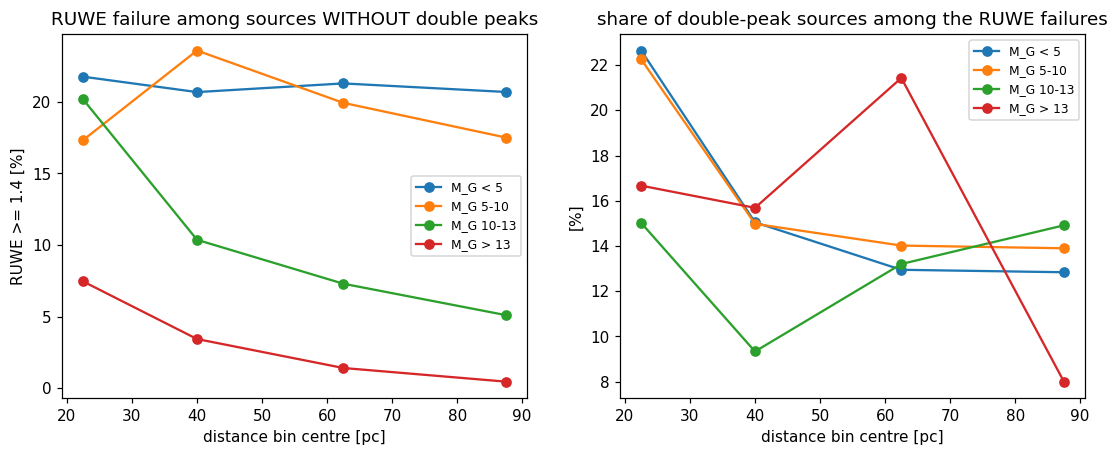

In [18]:
IPD_MIN = 0      # a source counts as "double peak seen" if ipd_frac_multi_peak > IPD_MIN

ipd = df["source_id"].map(gcns.set_index("source_id")["ipd_frac_multi_peak"])
has_ipd = ipd.notna()
dbl = has_ipd & (ipd > IPD_MIN)
print(f"Sources without GCNS match (no ipd value, left out): {int((~has_ipd).sum()):,} of {len(df):,}\n")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
for lo, hi, label in CLASSES:
    rows = []
    for d0, d1 in zip(DBINS[:-1], DBINS[1:]):
        m = df["other"] & has_ipd & in_class(df["mg"], lo, hi) & (df["dist_pc"] >= d0) & (df["dist_pc"] < d1)
        f = df["fail_ruwe"]
        n_all, n_single, n_dbl = int(m.sum()), int((m & ~dbl).sum()), int((m & dbl).sum())
        rows.append(dict(bin=f"{d0}-{d1} pc", n=n_all,
                         fail_all=wilson(int((m & f).sum()), n_all)[0],
                         fail_no_double_peak=wilson(int((m & ~dbl & f).sum()), n_single)[0],
                         fail_double_peak=wilson(int((m & dbl & f).sum()), n_dbl)[0],
                         double_peak_share_all=100 * n_dbl / max(n_all, 1),
                         double_peak_share_of_failures=100 * (m & dbl & f).sum() / max((m & f).sum(), 1)))
    t = pd.DataFrame(rows)
    print(label)
    print(t.to_string(index=False, float_format=lambda v: f"{v:.1f}"))
    print()
    x = [0.5 * (a + b) for a, b in zip(DBINS[:-1], DBINS[1:])]
    axes[0].plot(x, t["fail_no_double_peak"], marker="o", label=label)
    axes[1].plot(x, t["double_peak_share_of_failures"], marker="o", label=label)
axes[0].set_title("RUWE failure among sources WITHOUT double peaks"); axes[0].set_ylabel("RUWE >= 1.4 [%]")
axes[1].set_title("share of double-peak sources among the RUWE failures"); axes[1].set_ylabel("[%]")
for ax in axes:
    ax.set_xlabel("distance bin centre [pc]"); ax.legend(fontsize=8)
fig.savefig(FIG / "01.1_ruwe_double_peak.png")
plt.show()

**How to read it.** Left panel: if the M_G 5-10 line falls smoothly (no bump at 40 pc) once the double-peak sources are removed, the bump was made of marginally resolved pairs (B' supported). Right panel: B' predicts the M_G 5-10 line to peak at 30 to 50 pc. Also compare classes: B' expects the peak to sit nearer for fainter (lower mass) classes.

**Record your reading here:**

### 7.3 Resolved pairs inside our download (B)

**What.** Find pairs of sources in our download that are close on the sky and at the same distance: angular separation below `PAIR_MAX_ARCSEC`, parallax difference below `PAIR_NSIG` combined standard errors, and tangential velocity difference below `DV_MAX_KMS` (orbital motion of wide binaries is a few km/s). Then:
1. the share of stars with a companion at a projected separation of `S_RANGE_AU` (fixed in au, so that the same physical binaries are counted at every distance) by class and distance;
2. the RUWE failure rate as a function of the angular separation to the nearest companion;
3. the overlap with the GCNS list of resolved pairs.

**Prediction (B).** (1) falls with distance, because the closer pairs of the fixed au range become unresolved. (2) is highest at the smallest separations and approaches the rate of stars without companions at large separations.

**Cost.** A companion is only found if it is itself in our download (parallax_over_error ≥ 10), so faint companions are lost more often at larger distance; this also makes (1) fall. Read (1) as consistent with B, not as proof. Chance alignments are rare with the parallax and velocity conditions (about 9 sources per square degree in our download).

**Exercise.** Change `S_RANGE_AU` to (100, 1000) and (1000, 5000): wider pairs stay resolved at all distances, so the fall in (1) should weaken.

Candidate pairs within 60 arcsec: 32,913; physical (parallax and velocity agree): 25,786

(1) Share of stars with a companion at 20-1000 au [%] (photometric cuts applied):
    class  15-30 pc  30-50 pc  50-75 pc  75-100 pc
  M_G < 5     19.81     14.20     12.39       9.75
 M_G 5-10     14.97     11.27      9.46       7.67
M_G 10-13      7.58      6.03      4.89       3.83
 M_G > 13      5.83      5.40      4.46       3.58

(2) RUWE failure by angular separation to the nearest companion (all classes, photometric cuts applied):
 nearest companion      n  RUWE >= 1.4 [%]   lo    hi
        0-1 arcsec      1            100.0 20.7 100.0
        1-2 arcsec    592             12.2  9.8  15.0
        2-4 arcsec   4234             12.0 11.0  13.0
        4-8 arcsec   5799             12.4 11.6  13.3
       8-16 arcsec   5422             13.1 12.2  14.0
      16-60 arcsec   6955             13.2 12.5  14.0
no companion found 207319             12.5 12.4  12.7

(3) GCNS resolved pairs with both 

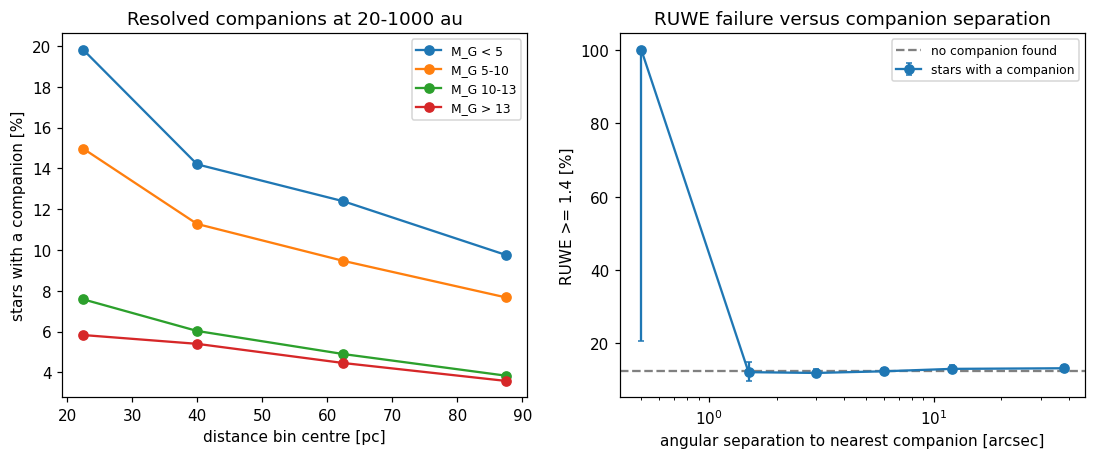

In [19]:
PAIR_MAX_ARCSEC = 60.0
PAIR_NSIG = 3.0
DV_MAX_KMS = 10.0
S_RANGE_AU = (20.0, 1000.0)
THETA_BINS = [0, 1, 2, 4, 8, 16, 60]

coords = SkyCoord(df["ra"].to_numpy() * u.deg, df["dec"].to_numpy() * u.deg)
i1, i2, sep2d, _ = coords.search_around_sky(coords, PAIR_MAX_ARCSEC * u.arcsec)
k = i1 < i2
i1, i2, theta = i1[k], i2[k], sep2d[k].arcsec
plx, eplx = df["parallax"].to_numpy(), df["parallax_error"].to_numpy()
pmra, pmdec = df["pmra"].to_numpy(), df["pmdec"].to_numpy()
plx_m = 0.5 * (plx[i1] + plx[i2])
ok_plx = np.abs(plx[i1] - plx[i2]) < PAIR_NSIG * np.hypot(eplx[i1], eplx[i2])
dv = 4.74 * np.hypot(pmra[i1] - pmra[i2], pmdec[i1] - pmdec[i2]) / plx_m
pairs = pd.DataFrame({"i1": i1, "i2": i2, "theta": theta, "s_au": theta * 1000 / plx_m})[ok_plx & (dv < DV_MAX_KMS)]
print(f"Candidate pairs within {PAIR_MAX_ARCSEC:.0f} arcsec: {k.sum():,}; physical (parallax and velocity agree): {len(pairs):,}")

# per star: nearest companion and whether it has a companion in the fixed au range
long = pd.concat([pairs.rename(columns={"i1": "i", "i2": "j"}), pairs.rename(columns={"i2": "i", "i1": "j"})])
nearest = long.groupby("i")["theta"].min()
inrange = long[(long["s_au"] >= S_RANGE_AU[0]) & (long["s_au"] < S_RANGE_AU[1])].groupby("i").size()
df["theta_comp"] = np.nan
df.loc[df.index[nearest.index], "theta_comp"] = nearest.to_numpy()
df["comp_in_range"] = False
df.loc[df.index[inrange.index], "comp_in_range"] = True

rows = []
for lo, hi, label in CLASSES:
    row = {"class": label}
    for d0, d1 in zip(DBINS[:-1], DBINS[1:]):
        m = df["other"] & in_class(df["mg"], lo, hi) & (df["dist_pc"] >= d0) & (df["dist_pc"] < d1)
        row[f"{d0}-{d1} pc"] = 100 * df.loc[m, "comp_in_range"].mean() if m.sum() >= 30 else np.nan
    rows.append(row)
frac = pd.DataFrame(rows)
print(f"\n(1) Share of stars with a companion at {S_RANGE_AU[0]:.0f}-{S_RANGE_AU[1]:.0f} au [%] (photometric cuts applied):")
print(frac.to_string(index=False, float_format=lambda v: f"{v:.2f}"))

rows = []
base = df["other"]
for a, b in zip(THETA_BINS[:-1], THETA_BINS[1:]):
    m = base & (df["theta_comp"] >= a) & (df["theta_comp"] < b)
    rows.append((f"{a}-{b} arcsec", int(m.sum()), *wilson(int((m & df["fail_ruwe"]).sum()), int(m.sum()))))
m = base & df["theta_comp"].isna()
rows.append(("no companion found", int(m.sum()), *wilson(int((m & df["fail_ruwe"]).sum()), int(m.sum()))))
q4b = pd.DataFrame(rows, columns=["nearest companion", "n", "RUWE >= 1.4 [%]", "lo", "hi"])
print("\n(2) RUWE failure by angular separation to the nearest companion (all classes, photometric cuts applied):")
print(q4b.to_string(index=False, float_format=lambda v: f"{v:.1f}"))

ids = df["source_id"].to_numpy()
ours = {frozenset((ids[a], ids[b])) for a, b in zip(pairs["i1"], pairs["i2"])}
in_df = resolved["source_id1"].isin(df["source_id"]) & resolved["source_id2"].isin(df["source_id"])
theirs = {frozenset(p) for p in zip(resolved.loc[in_df, "source_id1"], resolved.loc[in_df, "source_id2"])}
print(f"\n(3) GCNS resolved pairs with both stars in our download: {len(theirs):,}; also found by us: "
      f"{len(theirs & ours):,} ({100 * len(theirs & ours) / max(len(theirs), 1):.0f} %). "
      f"Our pairs also in the GCNS list: {100 * len(theirs & ours) / max(len(ours), 1):.0f} %")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
x = [0.5 * (a + b) for a, b in zip(DBINS[:-1], DBINS[1:])]
for _, r in frac.iterrows():
    axes[0].plot(x, r.drop("class").astype(float).to_numpy(), marker="o", label=r["class"])
axes[0].set_xlabel("distance bin centre [pc]"); axes[0].set_ylabel("stars with a companion [%]")
axes[0].set_title(f"Resolved companions at {S_RANGE_AU[0]:.0f}-{S_RANGE_AU[1]:.0f} au"); axes[0].legend(fontsize=8)
t = q4b.iloc[:-1]
xc = [0.5 * (a + b) for a, b in zip(THETA_BINS[:-1], THETA_BINS[1:])]
axes[1].errorbar(xc, t["RUWE >= 1.4 [%]"], yerr=[t["RUWE >= 1.4 [%]"] - t["lo"], t["hi"] - t["RUWE >= 1.4 [%]"]],
                 marker="o", capsize=2, label="stars with a companion")
axes[1].axhline(q4b.iloc[-1]["RUWE >= 1.4 [%]"], color="grey", ls="--", label="no companion found")
axes[1].set_xscale("log"); axes[1].set_xlabel("angular separation to nearest companion [arcsec]")
axes[1].set_ylabel("RUWE >= 1.4 [%]"); axes[1].set_title("RUWE failure versus companion separation"); axes[1].legend(fontsize=8)
fig.savefig(FIG / "01.1_pairs.png")
plt.show()

**How to read it.**
- *(1) and left panel:* B predicts falling lines. Remember the cost: part of the fall comes from faint companions dropping out of our download.
- *(2) and right panel:* if stars with a companion closer than a few arcsec fail RUWE far more often than stars without companions, a near neighbour disturbs the astrometry. That is the visible tail of the marginally resolved regime of 7.2.
- *(3):* a high overlap with the GCNS list means our simple pair search finds the same systems as the published one; a low overlap means the two use different criteria (the GCNS list also has projected separations far beyond ours).

**Record your reading here:**

### 7.4 At what distance does a typical binary look marginally resolved?

**What.** A small table, no data: angular separation = separation in au / distance in pc, for typical separations (M dwarfs 4 to 20 au, Winters et al. 2019; solar-type stars about 50 au, Raghavan et al. 2010). Values inside the marginally resolved range (about 0.1 to 0.7 arcsec; literature, Section 8.4) are marked with an asterisk.

**Why.** It turns hypothesis B' into a concrete expectation: where the asterisks sit for a class is where its RUWE failure rate should peak.

In [20]:
SEPARATIONS_AU = [4, 10, 20, 50, 100]
DISTANCES_PC = [15, 22.5, 40, 62.5, 87.5]
MARGINAL_ARCSEC = (0.1, 0.7)

rows = []
for a in SEPARATIONS_AU:
    row = {"separation [au]": a}
    for d in DISTANCES_PC:
        th = a / d
        row[f"{d} pc"] = f"{th:.2f}{' *' if MARGINAL_ARCSEC[0] <= th <= MARGINAL_ARCSEC[1] else ''}"
    rows.append(row)
print("Angular separation [arcsec]; * = inside the marginally resolved range")
print(pd.DataFrame(rows).to_string(index=False))

Angular separation [arcsec]; * = inside the marginally resolved range
 separation [au]  15 pc 22.5 pc  40 pc 62.5 pc 87.5 pc
               4 0.27 *  0.18 * 0.10 *    0.06    0.05
              10 0.67 *  0.44 * 0.25 *  0.16 *  0.11 *
              20   1.33    0.89 0.50 *  0.32 *  0.23 *
              50   3.33    2.22   1.25    0.80  0.57 *
             100   6.67    4.44   2.50    1.60    1.14


**Record your reading here:**

## 8. Question 5: do more observations mean more RUWE failures?

**What.** At fixed class and distance bin, split the stars into four groups (quartiles) by `visibility_periods_used`, the number of separate time windows in which Gaia observed the star, and compare the RUWE failure rate. Gaia's scanning pattern gives some parts of the sky many more visits than others, mainly as a function of ecliptic latitude. So the comparison is repeated inside three bands of |ecliptic latitude|.

**Competing hypotheses.**

| Hypothesis | Supported if |
|---|---|
| H5a test power: more observations make the same wobble easier to detect | in most class and distance bins, the top quartile fails more often than the bottom quartile, also inside the ecliptic-latitude bands |
| H5b no effect: RUWE is normalised by the number of observations, so the signal depends on wobble size and per-observation precision, not on the count (my reasoning) | differences scatter around zero |
| H5c sky position: the apparent effect comes from where on the sky stars with many visits lie (crowding, scanning geometry) | a difference appears overall but shrinks to near zero inside the ecliptic-latitude bands |

**Expectation.** I expect at most a weak effect and do not commit to one hypothesis.

**Exercise.** Change `ECL_BANDS` (for example 0, 30, 60, 90) or use `N_QUANT = 3`.

    class       bin     n vpu Q1 range vpu Q4 range  fail Q1 [%]  fail Q2 [%]  fail Q3 [%]  fail Q4 [%]  Q4 - Q1 overall  Q4 - Q1 within ecl. bands
  M_G < 5  15-30 pc   429         9-15        22-32         34.3         21.5         26.2         16.8            -17.4                      -11.5
  M_G < 5  30-50 pc  1986         9-15        23-31         22.5         20.6         22.8         21.1             -1.4                       -5.2
  M_G < 5  50-75 pc  5885         9-15        24-32         23.8         21.5         21.1         21.3             -2.5                       -4.4
  M_G < 5 75-100 pc 11299         9-16        25-32         22.7         20.7         21.3         20.6             -2.1                       -3.4
 M_G 5-10  15-30 pc  2018        11-16        25-32         20.6         18.3         18.5         14.9             -5.7                        0.6
 M_G 5-10  30-50 pc  8621         9-16        25-32         29.0         25.1         22.9         20.0         

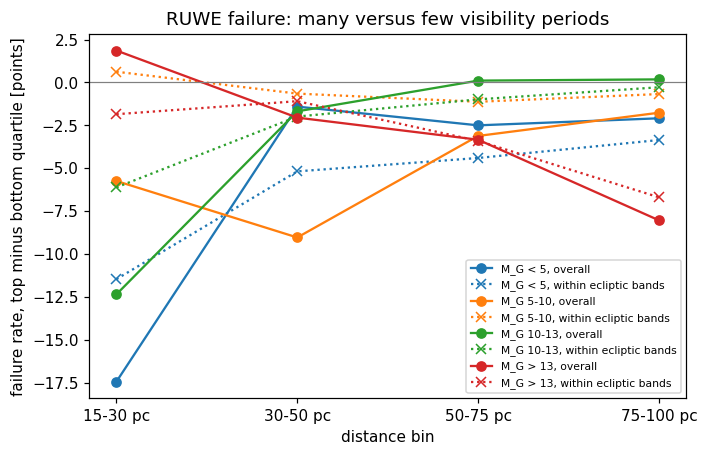

In [21]:
N_QUANT = 4
ECL_BANDS = [0, 20, 45, 90]

rows = []
for lo, hi, label in CLASSES:
    for d0, d1 in zip(DBINS[:-1], DBINS[1:]):
        m = df["other"] & in_class(df["mg"], lo, hi) & (df["dist_pc"] >= d0) & (df["dist_pc"] < d1)
        s = df.loc[m, ["visibility_periods_used", "fail_ruwe", "ecl_lat"]]
        if len(s) < 200:
            continue
        q = pd.qcut(s["visibility_periods_used"].rank(method="first"), N_QUANT, labels=False)
        rates = s.groupby(q)["fail_ruwe"].mean() * 100
        # same comparison inside ecliptic-latitude bands, averaged with weights = stars per band
        diffs, weights = [], []
        for e0, e1 in zip(ECL_BANDS[:-1], ECL_BANDS[1:]):
            sb = s[s["ecl_lat"].abs().between(e0, e1, inclusive="left")]
            if len(sb) < 100:
                continue
            qb = pd.qcut(sb["visibility_periods_used"].rank(method="first"), N_QUANT, labels=False)
            rb = sb.groupby(qb)["fail_ruwe"].mean() * 100
            diffs.append(rb.iloc[-1] - rb.iloc[0]); weights.append(len(sb))
        rows.append(dict(**{"class": label, "bin": f"{d0}-{d1} pc", "n": len(s),
                            "vpu Q1 range": f"{int(s['visibility_periods_used'][q == 0].min())}-{int(s['visibility_periods_used'][q == 0].max())}",
                            "vpu Q4 range": f"{int(s['visibility_periods_used'][q == N_QUANT - 1].min())}-{int(s['visibility_periods_used'][q == N_QUANT - 1].max())}"},
                         **{f"fail Q{i + 1} [%]": rates.iloc[i] for i in range(N_QUANT)},
                         **{"Q4 - Q1 overall": rates.iloc[-1] - rates.iloc[0],
                            "Q4 - Q1 within ecl. bands": np.average(diffs, weights=weights) if diffs else np.nan}))
q5 = pd.DataFrame(rows)
print(q5.to_string(index=False, float_format=lambda v: f"{v:.1f}"))

fig, ax = plt.subplots(figsize=(7, 4.3))
for lo, hi, label in CLASSES:
    t = q5[q5["class"] == label]
    ax.plot(t["bin"], t["Q4 - Q1 overall"], marker="o", label=f"{label}, overall")
    ax.plot(t["bin"], t["Q4 - Q1 within ecl. bands"], marker="x", ls=":", color=ax.lines[-1].get_color(),
            label=f"{label}, within ecliptic bands")
ax.axhline(0, color="grey", lw=0.8)
ax.set_ylabel("failure rate, top minus bottom quartile [points]"); ax.set_xlabel("distance bin")
ax.set_title("RUWE failure: many versus few visibility periods"); ax.legend(fontsize=7)
fig.savefig(FIG / "01.1_visibility_periods.png")
plt.show()

**How to read it.** Each row compares stars of one class and distance that differ only in how often Gaia saw them. "Q4 - Q1 overall" is the difference in percentage points between the most and least observed quarter; "within ecl. bands" is the same comparison inside bands of similar sky position. Consistently positive values in both columns support H5a; values near zero support H5b; a positive overall value that vanishes inside the bands supports H5c. With a few thousand stars per bin, differences of 1 to 2 points are within noise.

**Record your reading here:**

## 9. Summary

Fill in after running. One line per question: the prediction made before running, what came out, and whether the prediction held. If it did not, say so and why.

| Question | Prediction | Result | Held? |
|---|---|---|---|
| 1 M_G < 5 rise | H1: about 17 % of the class missing within 30 pc, nearly all with Hp < 6 to 7; corrected curve flat | | |
| 2 Hyades | purity near 0.8 (ring estimate); main recall losses from RUWE and from the proper-motion circle | | |
| 3 GCNS | losses by class as listed in section 6; extra sources concentrated in the plane; GCNS curve for M_G < 5 rises too | | |
| 4 RUWE peak | A too small; B' carries the peak; D and E minor | | |
| 5 visibility periods | weak or no effect | | |

**Consequences for later notebooks:** (to fill in)